# 26SU-2 uNmax Velocity Contour Workflow

This notebook is ordered from older local analytic references near the top to newer direct numerical and downloaded cluster checks near the bottom. The main flow is:

1. shared setup and bag calibration;
2. local analytic reference scans and adaptive contour visualization;
3. notebook-scale direct `uNmax` scan and analytic-vs-numerical comparison;
4. single-profile inspection;
5. downloaded 1Jun cluster payload visualization and overlay against the local analytic boundary.

Low-priority historical diagnostics were moved to `local_analysis_results/notebook_archive/26SU-2-archived-low-priority-cells.ipynb`.


## Common Setup

Imports shared packages, reloads local solver modules, and defines constants used by the rest of the notebook.


In [1]:
# SETUP
from pathlib import Path
import os
import sys
import importlib
import multiprocessing as mp

os.environ.setdefault("MPLCONFIGDIR", str((Path.cwd() / ".mpl-cache").resolve()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display
from scipy.optimize import brentq
from scipy.interpolate import interp1d
from tqdm.auto import tqdm

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
import RMFsolver.phase_velocity as phase_velocity
from RMFsolver.SQMsolver import PQM
from RMFsolver.Solver import RMFpressurePNM

phase_velocity = importlib.reload(phase_velocity)
solve_front_energy_conserving_uNmax = phase_velocity.solve_front_energy_conserving_uNmax

required_packages = [
    "numpy",
    "pandas",
    "matplotlib",
    "scipy",
    "tqdm",
    "IPython",
    "RMFsolver",
]

plt.rcParams.update({
    "figure.figsize": (7.5, 5.8),
    "axes.grid": True,
    "grid.alpha": 0.22,
    "font.size": 12,
    "axes.linewidth": 1.1,
    "xtick.direction": "in",
    "ytick.direction": "in",
})

n0 = 0.16 * const.MeV_fm**3
param = para.paraQMCRMF3
NM_type = "PNM"
ms = 0.0
TQstar_target = 0.1

print("26SU-2 velocity contour scan")
print(f"n0 = {n0:.6e} MeV^3")
print("Using ms=0, para.paraQMCRMF3, pure neutron matter")
print(f"uNmax target: exact T_Qstar={TQstar_target:g} MeV")
print("Required packages loaded:", ", ".join(required_packages))


26SU-2 velocity contour scan
n0 = 1.229361e+06 MeV^3
Using ms=0, para.paraQMCRMF3, pure neutron matter
uNmax target: exact T_Qstar=0.1 MeV
Required packages loaded: numpy, pandas, matplotlib, scipy, tqdm, IPython, RMFsolver


/Users/janshao/NSM_related/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Bag Calibration

Calibrates the bag constant from the selected critical density before any analytic or numerical scan is run.


In [2]:
# BAG_CALIBRATION_FROM_NCRIT
# Calibrate B^(1/4) so that the T=0 phase transition critical density is 3 n0.

nB_crit = 3.0 * n0
muK_crit = 0.0


def pnm_pressure_muB(mu_B, T, param=param):
    value = RMFpressurePNM(
        input_num=float(mu_B),
        input_type="muB",
        Trmf=float(T),
        para=param,
        sigma_init=30,
        w0_init=20,
        r03_init=-3,
        mub_init=max(990.0, float(mu_B)),
        verb=False,
    )
    if value is None:
        return np.nan
    return float(np.asarray(value).item())


def pnm_pressure_nB(n_B, T, param=param):
    value = RMFpressurePNM(
        input_num=float(n_B),
        input_type="nB",
        Trmf=float(T),
        para=param,
        sigma_init=30,
        w0_init=20,
        r03_init=-3,
        mub_init=990.0,
        verb=False,
    )
    if value is None:
        return np.nan
    return float(np.asarray(value).item())


def qm_pressure_muB(mu_B, T, B_one_forth, mu_K=muK_crit, m_s=ms):
    return float(PQM(float(mu_B), float(mu_K), float(B_one_forth), float(T), ms=float(m_s)))


def _safe_eval(func, x):
    try:
        value = float(func(float(x)))
    except Exception:
        return np.nan
    if not np.isfinite(value):
        return np.nan
    return value


def find_root_on_grid(func, x_grid, prefer=None):
    x_grid = np.asarray(x_grid, dtype=float)
    values = np.array([_safe_eval(func, x) for x in x_grid], dtype=float)
    finite = np.isfinite(values)
    x_grid = x_grid[finite]
    values = values[finite]
    if x_grid.size < 2:
        raise RuntimeError("Not enough finite samples to bracket a root")
    zero_hits = np.where(np.isclose(values, 0.0, atol=1.0e-8, rtol=0.0))[0]
    if zero_hits.size:
        return float(x_grid[zero_hits[0]])
    sign_changes = np.where(values[:-1] * values[1:] < 0.0)[0]
    if sign_changes.size == 0:
        raise RuntimeError("No sign change found on the requested grid")
    if prefer is None:
        idx = int(sign_changes[0])
    else:
        midpoints = 0.5 * (x_grid[sign_changes] + x_grid[sign_changes + 1])
        idx = int(sign_changes[np.argmin(np.abs(midpoints - float(prefer)))])
    return float(brentq(func, float(x_grid[idx]), float(x_grid[idx + 1]), xtol=1.0e-6, rtol=1.0e-8, maxiter=200))


def solve_bag_constant_from_ncrit0(ncrit0):
    mu_grid = np.linspace(900.0, 1500.0, 220)
    B_grid = np.linspace(120.0, 260.0, 281)
    P_crit0 = pnm_pressure_nB(ncrit0, 0.0)
    muB_crit0 = find_root_on_grid(
        lambda mu: pnm_pressure_muB(mu, 0.0) - P_crit0,
        mu_grid,
        prefer=1050.0,
    )
    B_one_forth = find_root_on_grid(
        lambda B: qm_pressure_muB(muB_crit0, 0.0, B) - P_crit0,
        B_grid,
        prefer=180.0,
    )
    return P_crit0, muB_crit0, B_one_forth


P_crit0, muB_crit0, B14 = solve_bag_constant_from_ncrit0(nB_crit)

calibration_summary = pd.DataFrame([
    {
        "B14_calibrated_MeV": B14,
        "nB_crit_over_n0": nB_crit / n0,
        "nB_crit_MeV3": nB_crit,
        "P_crit0_MeV4": P_crit0,
        "muB_crit0_MeV": muB_crit0,
        "ms_MeV": ms,
        "NM_type": NM_type,
    }
])
display(calibration_summary)


,B14_calibrated_MeV,nB_crit_over_n0,nB_crit_MeV3,P_crit0_MeV4,muB_crit0_MeV,ms_MeV,NM_type
0,189.156596,3.0,3.688082e+06,6.070174e+08,1190.93412,0.0,PNM


## Local Analytic Velocity Scan

Older local reference calculation using the hydro-consistent analytic velocity formula on the shared temperature/metastability grid. Outputs are saved under `local_analysis_results/`.


In [3]:
# ANALYTIC_VELOCITY_CONTOUR_SCAN
# Fast analytic contour scans using phase_velocity.analytic_velocity_bound.
from pathlib import Path
import importlib

import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import brentq
from tqdm.auto import tqdm

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
from RMFsolver import phase_velocity

phase_velocity = importlib.reload(phase_velocity)
analytic_velocity_bound = phase_velocity.analytic_velocity_bound

# Edit these values to control the saved analytic linear temperature mesh.
analytic_temperature_min_MeV = 0.1
analytic_temperature_max_MeV = 100.0
analytic_temperature_count = 150
analytic_metastability_values = np.linspace(0.01, 0.9, 35)
analytic_temperature_meshes_to_run = ("linear",)
analytic_force_recompute = False
analytic_xi = 0.0
analytic_closure_label = "hydro_jump_eigenvalue"

analytic_scan_output_dir = Path("local_analysis_results/22May/state_of_art")
analytic_scan_output_dir.mkdir(parents=True, exist_ok=True)
analytic_scan_npy_paths = {
    "linear": analytic_scan_output_dir / "26SU-2-hydro-analytic-velocity-contour-linear_v1.npy",
}

n0 = globals().get("n0", 0.16 * const.MeV_fm**3)
param = globals().get("param", para.paraQMCRMF3)
NM_type = globals().get("NM_type", "PNM")
ms = globals().get("ms", 0.0)
nB_crit = globals().get("nB_crit", 3.0 * n0)


def _analytic_temperature_values(mesh_label):
    mesh_label = str(mesh_label).lower()
    if mesh_label == "linear":
        return np.linspace(
            float(analytic_temperature_min_MeV),
            float(analytic_temperature_max_MeV),
            int(analytic_temperature_count),
        )
    if mesh_label == "log":
        if float(analytic_temperature_min_MeV) <= 0.0:
            raise RuntimeError("Log temperature mesh requires analytic_temperature_min_MeV > 0")
        return np.geomspace(
            float(analytic_temperature_min_MeV),
            float(analytic_temperature_max_MeV),
            int(analytic_temperature_count),
        )
    raise RuntimeError(f"Unknown analytic temperature mesh {mesh_label!r}; use 'linear' or 'log'")


def _analytic_calibration_root(func, x_grid, prefer):
    x_grid = np.asarray(x_grid, dtype=float)
    values = []
    for x in x_grid:
        try:
            value = float(func(float(x)))
        except Exception:
            value = np.nan
        values.append(value if np.isfinite(value) else np.nan)
    values = np.asarray(values, dtype=float)
    finite = np.isfinite(values)
    x_grid = x_grid[finite]
    values = values[finite]
    if x_grid.size < 2:
        raise RuntimeError("Not enough finite samples to bracket the analytic calibration root")
    zero_hits = np.where(np.isclose(values, 0.0, atol=1.0e-8, rtol=0.0))[0]
    if zero_hits.size:
        return float(x_grid[zero_hits[np.argmin(np.abs(x_grid[zero_hits] - float(prefer)))]])
    sign_changes = np.where(values[:-1] * values[1:] < 0.0)[0]
    if sign_changes.size == 0:
        raise RuntimeError("No sign change found for the analytic calibration root")
    midpoints = 0.5 * (x_grid[sign_changes] + x_grid[sign_changes + 1])
    idx = int(sign_changes[np.argmin(np.abs(midpoints - float(prefer)))])
    return float(brentq(func, float(x_grid[idx]), float(x_grid[idx + 1]), xtol=1.0e-6, rtol=1.0e-8, maxiter=200))


B14 = globals().get("B14", np.nan)
try:
    B14 = float(B14)
except Exception:
    B14 = np.nan

if (not np.isfinite(B14)) or B14 <= 0.0:
    # Keep the analytic branch independent: calibrate B from nB_crit(T=0)=3n0
    # whenever the notebook global B14 is missing or has been poisoned with NaN.
    P_crit0 = phase_velocity.PNM_n(nB_crit, 0.0, param=param, NM_type=NM_type)
    muB_crit0 = _analytic_calibration_root(
        lambda mu: phase_velocity.PNM(mu, 0.0, param=param, NM_type=NM_type) - P_crit0,
        np.linspace(900.0, 1500.0, 220),
        prefer=1050.0,
    )
    B14 = _analytic_calibration_root(
        lambda B: phase_velocity.PQM(muB_crit0, 0.0, B, 0.0, ms=ms) - P_crit0,
        np.linspace(120.0, 260.0, 281),
        prefer=180.0,
    )


def _analytic_point_key(T, metastability):
    return (round(float(T), 12), round(float(metastability), 12))


def _analytic_as_float(value):
    try:
        value = float(value)
    except Exception:
        return np.nan
    return value if np.isfinite(value) else np.nan


def _analytic_nB_residual(muB, T, nB_target):
    return float(
        phase_velocity.nB_NM(
            float(muB),
            float(T),
            param=param,
            NM_type=NM_type,
        ) - float(nB_target)
    )


def _analytic_muB_from_nB(nB_target, T, prefer=1100.0):
    nB_target = float(nB_target)
    T = float(T)
    prefer = float(prefer) if np.isfinite(float(prefer)) else 1100.0

    def residual(mu):
        return _analytic_nB_residual(mu, T, nB_target)

    bracket_widths = (20.0, 50.0, 100.0, 200.0, 400.0, 700.0)
    for width in bracket_widths:
        lo = max(1.0, prefer - width)
        hi = prefer + width
        try:
            f_lo = residual(lo)
            f_hi = residual(hi)
        except Exception:
            continue
        if not (np.isfinite(f_lo) and np.isfinite(f_hi)):
            continue
        if abs(f_lo) <= 1.0e-8 * max(abs(nB_target), 1.0):
            return float(lo)
        if abs(f_hi) <= 1.0e-8 * max(abs(nB_target), 1.0):
            return float(hi)
        if f_lo * f_hi < 0.0:
            return float(brentq(residual, lo, hi, xtol=1.0e-7, rtol=1.0e-10, maxiter=100))

    mu_grid = np.linspace(850.0, 1700.0, 80)
    values = np.full_like(mu_grid, np.nan, dtype=float)
    for i, mu_val in enumerate(mu_grid):
        try:
            values[i] = residual(mu_val)
        except Exception:
            values[i] = np.nan

    finite = np.isfinite(values)
    if np.count_nonzero(finite) < 2:
        raise RuntimeError("Could not evaluate enough finite nB_NM samples to invert muB_N")

    mu_finite = mu_grid[finite]
    val_finite = values[finite]
    exact_hits = np.where(np.isclose(val_finite, 0.0, rtol=0.0, atol=1.0e-8 * max(abs(nB_target), 1.0)))[0]
    if exact_hits.size:
        hit = exact_hits[np.argmin(np.abs(mu_finite[exact_hits] - prefer))]
        return float(mu_finite[hit])

    sign_changes = np.where(val_finite[:-1] * val_finite[1:] < 0.0)[0]
    if sign_changes.size == 0:
        raise RuntimeError("Could not bracket muB_N for the requested nB_N and T_N")

    midpoints = 0.5 * (mu_finite[sign_changes] + mu_finite[sign_changes + 1])
    idx = int(sign_changes[np.argmin(np.abs(midpoints - prefer))])
    return float(
        brentq(
            residual,
            float(mu_finite[idx]),
            float(mu_finite[idx + 1]),
            xtol=1.0e-7,
            rtol=1.0e-10,
            maxiter=100,
        )
    )


def _analytic_latest_rows(records):
    latest = {}
    for row in records:
        if "T_MeV" in row and "metastability" in row:
            latest[_analytic_point_key(row["T_MeV"], row["metastability"])] = row
    return latest


def _analytic_load_payload(path, mesh_label):
    if analytic_force_recompute or not Path(path).exists():
        return []
    payload = np.load(path, allow_pickle=True).item()
    records = list(payload.get("records", []))
    if not records:
        return []
    frame = pd.DataFrame.from_records(records)
    if frame.empty:
        return []
    keep = np.ones(len(frame), dtype=bool)
    if "temperature_mesh" in frame.columns:
        keep &= frame["temperature_mesh"].astype(str).str.lower().to_numpy() == str(mesh_label).lower()
    if "B14_calibrated_MeV" in frame.columns:
        cached_B14 = pd.to_numeric(frame["B14_calibrated_MeV"], errors="coerce").to_numpy(dtype=float)
        keep &= np.isfinite(cached_B14) & np.isclose(cached_B14, float(B14), rtol=1.0e-10, atol=1.0e-8)
    if "xi" in frame.columns:
        cached_xi = pd.to_numeric(frame["xi"], errors="coerce").to_numpy(dtype=float)
        keep &= np.isfinite(cached_xi) & np.isclose(cached_xi, float(analytic_xi), rtol=0.0, atol=1.0e-12)
    if "ms_MeV" in frame.columns:
        cached_ms = pd.to_numeric(frame["ms_MeV"], errors="coerce").to_numpy(dtype=float)
        keep &= np.isfinite(cached_ms) & np.isclose(cached_ms, float(ms), rtol=0.0, atol=1.0e-12)
    if "NM_type" in frame.columns:
        keep &= frame["NM_type"].astype(str).to_numpy() == str(NM_type)
    if "analytic_closure" in frame.columns:
        keep &= frame["analytic_closure"].astype(str).to_numpy() == str(analytic_closure_label)
    return frame.loc[keep].to_dict("records")


def _analytic_save_payload(path, mesh_label, temperature_values, records):
    payload = {
        "temperature_mesh": str(mesh_label),
        "temperature_axis_scale": str(mesh_label),
        "temperature_values": np.asarray(temperature_values, dtype=float),
        "metastability_values": np.asarray(analytic_metastability_values, dtype=float),
        "records": list(records),
        "B14": float(B14),
        "n0": float(n0),
        "nB_crit": float(nB_crit),
        "xi": float(analytic_xi),
        "ms_MeV": float(ms),
        "NM_type": str(NM_type),
        "analytic_closure": str(analytic_closure_label),
    }
    np.save(path, payload, allow_pickle=True)


analytic_scan_frames = []
analytic_scan_payloads = {}

for analytic_temperature_mesh in analytic_temperature_meshes_to_run:
    analytic_temperature_mesh = str(analytic_temperature_mesh).lower()
    analytic_temperature_values = _analytic_temperature_values(analytic_temperature_mesh)
    analytic_scan_npy_path = analytic_scan_npy_paths[analytic_temperature_mesh]
    analytic_records = _analytic_load_payload(analytic_scan_npy_path, analytic_temperature_mesh)
    analytic_latest = _analytic_latest_rows(analytic_records)

    progress_bar = tqdm(
        total=len(analytic_temperature_values) * len(analytic_metastability_values),
        desc=f"Analytic velocity ({analytic_temperature_mesh})",
        unit="pt",
        position=0,
        leave=True,
        dynamic_ncols=True,
        mininterval=0.5,
    )
    for T_N in analytic_temperature_values:
        previous_quark_guess = None
        previous_muB_N = 1100.0
        progress_bar.set_postfix_str(f"T={float(T_N):.3g} MeV", refresh=False)
        for metastability in analytic_metastability_values:
            key = _analytic_point_key(T_N, metastability)
            latest_row = analytic_latest.get(key)
            if latest_row is not None:
                latest_success = bool(latest_row.get("success", False))
                latest_endpoint = bool(latest_row.get("endpoint_domain_failure", False))
                if latest_success or latest_endpoint:
                    progress_bar.update(1)
                    continue

            nB_N = float(nB_crit + float(metastability) * n0)
            row = {
                "temperature_mesh": analytic_temperature_mesh,
                "T_MeV": float(T_N),
                "metastability": float(metastability),
                "nB_N_over_n0": float(nB_N / n0),
                "nB_N_MeV3": nB_N,
                "B14_calibrated_MeV": float(B14),
                "xi": float(analytic_xi),
                "ms_MeV": float(ms),
                "NM_type": NM_type,
                "endpoint_domain_failure": False,
                "analytic_closure": analytic_closure_label,
            }
            try:
                muB_N = _analytic_muB_from_nB(nB_N, float(T_N), prefer=previous_muB_N)
                result = analytic_velocity_bound(
                    muB_N,
                    float(T_N),
                    float(B14),
                    xi=float(analytic_xi),
                    ms=float(ms),
                    param=param,
                    NM_type=NM_type,
                    initial_guess=previous_quark_guess,
                )
                previous_muB_N = float(muB_N)
                previous_quark_guess = (float(result["muB_bar"]), float(result["T_Q"]))
                row.update({
                    "success": True,
                    "message": result.get("message", ""),
                    "muB_N_MeV": float(muB_N),
                    "u_N": float(result["u_N_max"]),
                    "u_N_m_s": float(result["u_N_max"] * const.m_per_sec),
                    "u_N_squared": float(result["u_N_squared"]),
                    "u_N_formula_squared": float(result["u_N_formula_squared"]),
                    "analytic_velocity_residual": float(result["analytic_velocity_residual"]),
                    "jB": float(result["jB"]),
                    "u_Q": float(result["u_Q"]),
                    "gamma_N": float(result["gamma_N"]),
                    "gamma_Q": float(result["gamma_Q"]),
                    "muB_bar_MeV": float(result["muB_bar"]),
                    "muB_Q_MeV": float(result["muB_Q"]),
                    "T_Q_MeV": float(result["T_Q"]),
                    "P_N_MeV4": float(result["P_N"]),
                    "P_Q_MeV4": float(result["P_Q"]),
                    "pressure_jump_MeV4": float(result["pressure_jump"]),
                    "pressure_jump_balance_MeV4": float(result["pressure_jump_balance"]),
                    "pressure_jump_residual_MeV4": float(result["pressure_jump_residual"]),
                    "energy_flux_residual": float(result["energy_flux_residual"]),
                    "momentum_flux_residual": float(result["momentum_flux_residual"]),
                    "endpoint_scaled_residual": float(result["endpoint_scaled_residual"]),
                    "mu_q_MeV": float(result["mu_q"]),
                    "nB_N_MeV3_check": float(result["nB_N"]),
                    "nB_Q_MeV3": float(result["nB_Q"]),
                    "h_N_MeV4": float(result["h_N"]),
                    "h_Q_MeV4": float(result["h_Q"]),
                    "h_over_nB_N_MeV": float(result["h_over_nB_N"]),
                    "h_over_nB_Q_MeV": float(result["h_over_nB_Q"]),
                    "a_N": float(result["a_N"]),
                    "aQstar_max": float(result["aQstar_max"]),
                    "muKstar_max_MeV": float(result["muKstar_max"]),
                    "muK_Qstar_MeV": float(result["muKstar_max"]),
                    "gamma_MeV": float(result["gamma"]),
                    "tau_MeV_inv": float(result["tau"]),
                    "tau_seconds": float(result["tau_seconds"]),
                    "slow_front_consistent": bool(result["slow_front_consistent"]),
                    "endpoint_domain_failure": False,
                })
            except Exception as exc:
                endpoint_domain_failure = "aQstar_max must satisfy 0 < aQstar_max < 1" in str(exc)
                row.update({
                    "success": False,
                    "message": repr(exc),
                    "muB_N_MeV": np.nan,
                    "u_N": np.nan,
                    "u_N_m_s": np.nan,
                    "u_N_squared": np.nan,
                    "u_N_formula_squared": np.nan,
                    "analytic_velocity_residual": np.nan,
                    "jB": np.nan,
                    "u_Q": np.nan,
                    "gamma_N": np.nan,
                    "gamma_Q": np.nan,
                    "muB_bar_MeV": np.nan,
                    "muB_Q_MeV": np.nan,
                    "T_Q_MeV": np.nan,
                    "P_N_MeV4": np.nan,
                    "P_Q_MeV4": np.nan,
                    "pressure_jump_MeV4": np.nan,
                    "pressure_jump_balance_MeV4": np.nan,
                    "pressure_jump_residual_MeV4": np.nan,
                    "energy_flux_residual": np.nan,
                    "momentum_flux_residual": np.nan,
                    "endpoint_scaled_residual": np.nan,
                    "mu_q_MeV": np.nan,
                    "nB_Q_MeV3": np.nan,
                    "h_N_MeV4": np.nan,
                    "h_Q_MeV4": np.nan,
                    "h_over_nB_N_MeV": np.nan,
                    "h_over_nB_Q_MeV": np.nan,
                    "a_N": np.nan,
                    "aQstar_max": np.nan,
                    "muKstar_max_MeV": np.nan,
                    "muK_Qstar_MeV": np.nan,
                    "gamma_MeV": np.nan,
                    "tau_MeV_inv": np.nan,
                    "tau_seconds": np.nan,
                    "slow_front_consistent": False,
                    "endpoint_domain_failure": bool(endpoint_domain_failure),
                })
            analytic_records.append(row)
            analytic_latest[key] = row
            progress_bar.update(1)

        _analytic_save_payload(analytic_scan_npy_path, analytic_temperature_mesh, analytic_temperature_values, analytic_records)

    progress_bar.close()
    _analytic_save_payload(analytic_scan_npy_path, analytic_temperature_mesh, analytic_temperature_values, analytic_records)
    analytic_frame = pd.DataFrame.from_records(analytic_records)
    analytic_scan_frames.append(analytic_frame)
    analytic_scan_payloads[analytic_temperature_mesh] = {
        "path": analytic_scan_npy_path,
        "temperature_values": analytic_temperature_values,
        "metastability_values": analytic_metastability_values,
        "records": analytic_records,
    }
    print(f"Saved {len(analytic_records)} {analytic_temperature_mesh} rows to {analytic_scan_npy_path}")

analytic_scan_df = pd.concat(analytic_scan_frames, ignore_index=True) if analytic_scan_frames else pd.DataFrame()
display(analytic_scan_df.tail())


Analytic velocity (linear): 100%|██████████| 5250/5250 [00:08<00:00, 583.74pt/s, T=100 MeV] 

Saved 5255 linear rows to local_analysis_results/22May/state_of_art/26SU-2-hydro-analytic-velocity-contour-linear_v1.npy


,temperature_mesh,T_MeV,metastability,nB_N_over_n0,nB_N_MeV3,B14_calibrated_MeV,xi,ms_MeV,NM_type,endpoint_domain_failure,...,h_over_nB_N_MeV,h_over_nB_Q_MeV,a_N,aQstar_max,muKstar_max_MeV,muK_Qstar_MeV,gamma_MeV,tau_MeV_inv,tau_seconds,slow_front_consistent
5250,linear,4.122819,0.245588,3.245588,3.989998e+06,189.156596,0.0,0.0,PNM,False,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False
5251,linear,12.838926,0.088529,3.088529,3.796916e+06,189.156596,0.0,0.0,PNM,False,...,1209.608860,1209.608860,0.589053,0.261307,69.194636,69.194636,1.981645e-12,5.046312e+11,3.321543e-10,True
5252,linear,14.850336,0.873824,3.873824,4.762326e+06,189.156596,0.0,0.0,PNM,False,...,1353.610579,1353.610579,0.627748,0.712120,193.099475,193.099475,2.231323e-12,4.481646e+11,2.949873e-10,True
5253,linear,59.771812,0.873824,3.873824,4.762326e+06,189.156596,0.0,0.0,PNM,False,...,1411.838143,1411.838143,0.628166,0.934982,247.567270,247.567270,1.980943e-12,5.048100e+11,3.322720e-10,True
5254,linear,74.522148,0.559706,3.559706,4.376162e+06,189.156596,0.0,0.0,PNM,False,...,1390.491211,1390.491211,0.617199,0.969453,250.015646,250.015646,1.736292e-12,5.759400e+11,3.790906e-10,True


## Local Adaptive Analytic Reference

Loads and visualizes the current local adaptive hydro-analytic contour payload, including the analytic endpoint boundary.


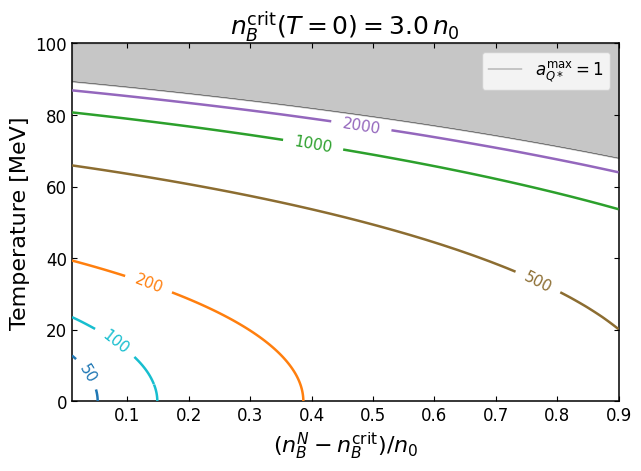

,file,grid,finite_velocity,u_min_m_s,u_max_m_s,aQstar_min,aQstar_max,boundary_T_min,boundary_T_max
0,local_analysis_results/22May/state_of_art/26SU...,150 x 35,5242,18.352604,52647.202623,0.072571,0.999957,67.957422,89.363403


In [4]:
# ADAPTIVE_HYDRO_ANALYTIC_VISUALIZATION
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

# Edit this path if you download a new adaptive cluster version.
adaptive_hydro_candidate_paths = [
    Path("local_analysis_results/22May/state_of_art/26SU-2-hydro-analytic-adaptive-contour__adaptive_v1.npy"),
    Path("26SU-2-hydro-analytic-adaptive-contour__adaptive_v1.npy"),
]
adaptive_hydro_npy_path = next((path for path in adaptive_hydro_candidate_paths if path.exists()), adaptive_hydro_candidate_paths[0])
adaptive_hydro_output_png_path = Path("local_analysis_results/22May/state_of_art/new_EoS_contour.pdf")
adaptive_hydro_output_png_path.parent.mkdir(parents=True, exist_ok=True)

# Editable plot controls.
adaptive_contour_levels_m_s = [50, 100, 200, 500, 1000, 2000]
adaptive_level_colors = {
    50.0: "#1f77b4",
    100.0: "#17becf",
    200.0: "#ff7f0e",
    500.0: "#8c6d31",
    1000.0: "#2ca02c",
    2000.0: "#9467bd",
    5000.0: "#d62728",
    1.0e4: "#e377c2",
    2.0e4: "#7f7f7f",
    5.0e4: "#bcbd22",
}
adaptive_cmap = "turbo"
adaptive_contour_linewidth = 1.8
adaptive_contour_label_fontsize = 11
adaptive_axis_fontsize = 16
adaptive_title_fontsize = 18
adaptive_tick_fontsize = 12
adaptive_legend_fontsize = 12
adaptive_figure_size = (6.3, 4.6)
adaptive_x_limits = (0.01, 0.9)
adaptive_y_limits = (0.0, 100.0)
adaptive_shade_color = "0.70"
adaptive_shade_alpha = 0.75
adaptive_boundary_color = "0.10"
adaptive_boundary_linewidth = 0.3
adaptive_boundary_linestyle = "-"
adaptive_save_png = True


def _load_payload(path):
    path = Path(path)
    if not path.exists():
        raise RuntimeError(f"Missing adaptive hydro file: {path}")
    return np.load(path, allow_pickle=True).item()


def _finite_levels(values, levels):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values) & (values > 0.0)]
    if values.size == 0:
        return np.array([], dtype=float)
    levels = np.asarray(levels, dtype=float)
    levels = levels[np.isfinite(levels) & (levels > 0.0)]
    return np.asarray([level for level in levels if values.min() <= level <= values.max()], dtype=float)


def _level_colors(levels):
    colors = []
    for level in levels:
        color = None
        for ref, ref_color in adaptive_level_colors.items():
            if np.isclose(float(level), float(ref)):
                color = ref_color
                break
        if color is None:
            return None
        colors.append(color)
    return colors


def _label_fmt(level):
    level = float(level)
    if abs(level) >= 1.0e4:
        exponent = int(np.floor(np.log10(abs(level))))
        mantissa = level / (10.0 ** exponent)
        mantissa_text = f"{mantissa:.1f}".rstrip("0").rstrip(".")
        return rf"${mantissa_text}\times10^{{{exponent}}}$"
    if abs(level) >= 100.0:
        return f"{level:.0f}"
    if abs(level) >= 10.0:
        return f"{level:.1f}".rstrip("0").rstrip(".")
    return f"{level:.2g}"


payload = _load_payload(adaptive_hydro_npy_path)
M_grid = np.asarray(payload["metastability_grid"], dtype=float)
T_grid = np.asarray(payload["temperature_grid"], dtype=float)
velocity_grid = np.asarray(payload["velocity_grid_m_s"], dtype=float)
aQstar_grid = np.asarray(payload["aQstar_grid"], dtype=float)
boundary_M = np.asarray(payload["boundary_metastability_values"], dtype=float)
boundary_T = np.asarray(payload["boundary_temperature_values"], dtype=float)
order = np.argsort(boundary_M)
boundary_M = boundary_M[order]
boundary_T = boundary_T[order]

masked_velocity = np.ma.masked_invalid(velocity_grid)
finite_velocity = velocity_grid[np.isfinite(velocity_grid) & (velocity_grid > 0.0)]
levels = _finite_levels(finite_velocity, adaptive_contour_levels_m_s)

fig, ax = plt.subplots(figsize=adaptive_figure_size, constrained_layout=True, facecolor="white")
ax.set_facecolor("white")
ax.grid(False)
ax.set_xlim(*adaptive_x_limits)
ax.set_ylim(*adaptive_y_limits)
ax.tick_params(labelsize=adaptive_tick_fontsize, direction="in", top=True, right=True)
ax.set_xlabel(r"$(n_B^N-n_B^{\rm crit})/n_0$", fontsize=adaptive_axis_fontsize)
ax.set_ylabel("Temperature [MeV]", fontsize=adaptive_axis_fontsize)
ax.set_title(r"$n_B^{\rm crit}(T=0)=3.0\,n_0$", fontsize=adaptive_title_fontsize)

# Forbidden endpoint-domain region, using the saved smooth aQstar_max=1 boundary.
ax.fill_between(
    boundary_M,
    boundary_T,
    adaptive_y_limits[1],
    color=adaptive_shade_color,
    alpha=adaptive_shade_alpha,
    zorder=0,
)
ax.plot(
    boundary_M,
    boundary_T,
    color=adaptive_boundary_color,
    linewidth=adaptive_boundary_linewidth,
    linestyle=adaptive_boundary_linestyle,
    zorder=4,
)

if levels.size:
    colors = _level_colors(levels)
    contour_kwargs = {
        "levels": levels,
        "linewidths": float(adaptive_contour_linewidth),
        "zorder": 3,
    }
    if colors is None:
        contour_kwargs["cmap"] = adaptive_cmap
    else:
        contour_kwargs["colors"] = colors
    contour = ax.contour(M_grid, T_grid, masked_velocity, **contour_kwargs)
    texts = ax.clabel(
        contour,
        contour.levels,
        inline=True,
        inline_spacing=8,
        fontsize=adaptive_contour_label_fontsize,
        fmt={level: _label_fmt(level) for level in contour.levels},
    )
    for text in texts:
        text.set_bbox(dict(facecolor="white", edgecolor="none", alpha=0.85, pad=0.6))
else:
    contour = None

ax.legend(
    handles=[Line2D([0], [0], color=adaptive_boundary_color, linewidth=adaptive_boundary_linewidth, label=r"$a_{Q*}^{\rm max}=1$")],
    loc="upper right",
    fontsize=adaptive_legend_fontsize,
    frameon=True,
)

if adaptive_save_png:
    fig.savefig(adaptive_hydro_output_png_path, dpi=220, facecolor="white")
plt.show()

display(pd.DataFrame([{
    "file": str(adaptive_hydro_npy_path),
    "grid": f"{velocity_grid.shape[0]} x {velocity_grid.shape[1]}",
    "finite_velocity": int(np.isfinite(velocity_grid).sum()),
    "u_min_m_s": float(np.nanmin(velocity_grid)),
    "u_max_m_s": float(np.nanmax(velocity_grid)),
    "aQstar_min": float(np.nanmin(aQstar_grid)),
    "aQstar_max": float(np.nanmax(aQstar_grid)),
    "boundary_T_min": float(np.nanmin(boundary_T)),
    "boundary_T_max": float(np.nanmax(boundary_T)),
}]))


## Direct uNmax 4x4 Scan

Runs the current small direct numerical `uNmax` scan used for notebook-scale testing.


In [5]:
# UNMAX_PARAMETER_SCAN
# Direct, resumable uNmax scan: one solver call per grid point.

from pathlib import Path
import importlib

import numpy as np
import pandas as pd
from scipy.optimize import brentq
from tqdm import tqdm

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
import RMFsolver.phase_velocity as phase_velocity
from RMFsolver.SQMsolver import PQM
from RMFsolver.Solver import RMFpressurePNM

phase_velocity = importlib.reload(phase_velocity)
solve_front_energy_conserving_uNmax = phase_velocity.solve_front_energy_conserving_uNmax

n0 = globals().get("n0", 0.16 * const.MeV_fm**3)
param = globals().get("param", para.paraQMCRMF3)
NM_type = globals().get("NM_type", "PNM")
ms = globals().get("ms", 0.0)
TQstar_target = globals().get("TQstar_target", 0.0)
nB_crit = globals().get("nB_crit", 3.0 * n0)
muK_crit = globals().get("muK_crit", 0.0)


def _scan_pnm_pressure_muB(mu_B, T):
    value = RMFpressurePNM(
        input_num=float(mu_B),
        input_type="muB",
        Trmf=float(T),
        para=param,
        sigma_init=30,
        w0_init=20,
        r03_init=-3,
        mub_init=max(990.0, float(mu_B)),
        verb=False,
    )
    return np.nan if value is None else float(np.asarray(value).item())


def _scan_pnm_pressure_nB(n_B, T):
    value = RMFpressurePNM(
        input_num=float(n_B),
        input_type="nB",
        Trmf=float(T),
        para=param,
        sigma_init=30,
        w0_init=20,
        r03_init=-3,
        mub_init=990.0,
        verb=False,
    )
    return np.nan if value is None else float(np.asarray(value).item())


def _scan_qm_pressure_muB(mu_B, T, B_one_forth):
    return float(PQM(float(mu_B), float(muK_crit), float(B_one_forth), float(T), ms=float(ms)))


def _scan_safe_eval(func, x):
    try:
        value = float(func(float(x)))
    except Exception:
        return np.nan
    return value if np.isfinite(value) else np.nan


def _scan_find_root_on_grid(func, x_grid, prefer=None):
    x_grid = np.asarray(x_grid, dtype=float)
    values = np.array([_scan_safe_eval(func, x) for x in x_grid], dtype=float)
    finite = np.isfinite(values)
    x_grid = x_grid[finite]
    values = values[finite]
    if x_grid.size < 2:
        raise RuntimeError("Not enough finite samples to bracket a root")
    sign_changes = np.where(values[:-1] * values[1:] < 0.0)[0]
    zero_hits = np.where(np.isclose(values, 0.0, atol=1.0e-8, rtol=0.0))[0]
    if zero_hits.size:
        return float(x_grid[zero_hits[0]])
    if sign_changes.size == 0:
        raise RuntimeError("No sign change found on the requested grid")
    if prefer is None:
        idx = int(sign_changes[0])
    else:
        midpoints = 0.5 * (x_grid[sign_changes] + x_grid[sign_changes + 1])
        idx = int(sign_changes[np.argmin(np.abs(midpoints - float(prefer)))])
    return float(brentq(func, float(x_grid[idx]), float(x_grid[idx + 1]), xtol=1.0e-6, rtol=1.0e-8, maxiter=200))


def _scan_solve_bag_constant_from_ncrit0(ncrit0):
    P_crit0 = _scan_pnm_pressure_nB(ncrit0, 0.0)
    muB_crit0 = _scan_find_root_on_grid(
        lambda mu: _scan_pnm_pressure_muB(mu, 0.0) - P_crit0,
        np.linspace(900.0, 1500.0, 220),
        prefer=1050.0,
    )
    B_one_forth = _scan_find_root_on_grid(
        lambda B: _scan_qm_pressure_muB(muB_crit0, 0.0, B) - P_crit0,
        np.linspace(120.0, 260.0, 281),
        prefer=180.0,
    )
    return P_crit0, muB_crit0, B_one_forth


if "B14" not in globals():
    P_crit0, muB_crit0, B14 = _scan_solve_bag_constant_from_ncrit0(nB_crit)
    print(
        "Calibrated B^(1/4) from nB_crit(T=0)=3 n0: "
        f"B14={B14:.6f} MeV, muB_crit0={muB_crit0:.6f} MeV"
    )

n_temperature_scan = 4
n_metastability_scan = 4
temperature_values = np.geomspace(5, 50, n_temperature_scan)
metastability_values = np.linspace(0.1, 0.5, n_metastability_scan)

output_dir = Path("csv_share")
output_dir.mkdir(exist_ok=True)


def _scan_float_label(value):
    value = float(value)
    if value == 0.0:
        return "0"
    return f"{value:.0e}".replace("+", "").replace("-", "m")


scan_target_label = f"TQstar{_scan_float_label(TQstar_target)}"
scan_pkl_path = output_dir / f"26SU-2-uNmax-{scan_target_label}-direct-velocity-contour.pkl"
scan_csv_path = output_dir / f"26SU-2-uNmax-{scan_target_label}-direct-velocity-contour.csv"

# Direct solver controls. Change TQstar_target above/globally to test small positive values.
tail_eps_scan = 1.0e-8
n_mesh_scan = 30
tol_bvp_scan = 5.0e-4
max_nodes_scan = 800
jB_bounds_scan = (1.0e-4, 5.0)
jB_guess_scan = 0.6
TQ_guess_scan = 20.0
return_profile_scan = False
verb_scan = False
force_update_scan = True


def _point_key(T, metastability):
    return (round(float(T), 12), round(float(metastability), 12))


def _scan_as_float(value):
    try:
        value = float(value)
    except Exception:
        return np.nan
    return value if np.isfinite(value) else np.nan


def _float_from_result(result, key):
    return _scan_as_float(result.get(key, np.nan))


def _scan_latest_rows(records):
    latest = {}
    for row in records:
        if "T_MeV" in row and "metastability" in row:
            latest[_point_key(row["T_MeV"], row["metastability"])] = row
    return latest


if force_update_scan:
    scan_df = pd.DataFrame()
    records = []
    latest_rows = {}
    successful_keys = set()
elif scan_pkl_path.exists():
    scan_df = pd.read_pickle(scan_pkl_path)
    records = scan_df.to_dict("records") if not scan_df.empty else []
    latest_rows = _scan_latest_rows(records)
    successful_keys = {key for key, row in latest_rows.items() if bool(row.get("success", False))}
else:
    scan_df = pd.DataFrame()
    records = []
    latest_rows = {}
    successful_keys = set()

total_points = len(temperature_values) * len(metastability_values)
if total_points != 16:
    raise RuntimeError(f"Expected a 4 x 4 uNmax scan, got {len(temperature_values)} x {len(metastability_values)}")
failed_to_retry = len(latest_rows) - len(successful_keys)
print(
    f"Loaded {len(records)} saved rows; {len(successful_keys)} successful latest points, "
    f"{failed_to_retry} failed latest points will be retried, {total_points} total grid points "
    f"({len(temperature_values)} x {len(metastability_values)}), force_update={force_update_scan}."
)

scan_progress = tqdm(
    total=total_points,
    initial=len(successful_keys),
    desc="uNmax scan",
    unit="point",
    dynamic_ncols=True,
)
try:
    for i_T, T_N in enumerate(temperature_values):
        row_label = f"T={float(T_N):.4g} MeV"
        scan_progress.set_postfix_str(row_label)
        for i_meta, metastability in enumerate(metastability_values):
            key = _point_key(T_N, metastability)
            if key in successful_keys:
                continue

            nB_N = nB_crit + float(metastability) * n0
            row = {
                "T_MeV": float(T_N),
                "metastability": float(metastability),
                "nB_N": float(nB_N),
                "nB_N_over_n0": float(nB_N / n0),
                "nB_crit": float(nB_crit),
                "nB_crit_over_n0": float(nB_crit / n0),
                "B14_calibrated_MeV": float(B14),
                "TQstar_target_MeV": float(TQstar_target),
                "ms_MeV": float(ms),
                "NM_type": NM_type,
                "param_name": "paraQMCRMF3",
                "grid_i_T": int(i_T),
                "grid_i_metastability": int(i_meta),
                "retried_existing_failure": bool(key in latest_rows and not bool(latest_rows[key].get("success", False))),
                "jB_trial": float(jB_guess_scan),
                "T_Q_trial": float(TQ_guess_scan),
            }
            scan_progress.write(
                f"Starting [{scan_progress.n + 1:03d}/{total_points}] "
                f"T={float(T_N):.4g} MeV, meta={float(metastability):.4g}, "
                f"nB_N/n0={float(nB_N / n0):.4g}, TQstar={float(TQstar_target):.4g}"
            )

            try:
                result = solve_front_energy_conserving_uNmax(
                    T=float(T_N),
                    nB_N=float(nB_N),
                    B_one_forth=float(B14),
                    TQstar=float(TQstar_target),
                    ms=float(ms),
                    param=param,
                    NM_type=NM_type,
                    tail_eps=tail_eps_scan,
                    n_mesh=n_mesh_scan,
                    tol_bvp=tol_bvp_scan,
                    max_nodes=max_nodes_scan,
                    jB_guess=float(jB_guess_scan),
                    TQ_guess=float(TQ_guess_scan),
                    jB_bounds=jB_bounds_scan,
                    return_profile=return_profile_scan,
                    verb=verb_scan,
                )
            except Exception as exc:
                result = {"success": False, "message": repr(exc)}

            result_success = bool(result.get("success", False))
            raw_u_N = _float_from_result(result, "raw_u_N")
            if not np.isfinite(raw_u_N):
                raw_u_N = _float_from_result(result, "u_N")
            raw_u_N_m_s = raw_u_N * const.m_per_sec
            raw_u_N_max_candidate = _float_from_result(result, "raw_u_N_max_candidate")
            if not np.isfinite(raw_u_N_max_candidate):
                raw_u_N_max_candidate = _float_from_result(result, "u_N_max_candidate")
            raw_jB = _float_from_result(result, "raw_jB")
            if not np.isfinite(raw_jB):
                raw_jB = _float_from_result(result, "jB")
            raw_aQstar = _float_from_result(result, "raw_aQstar")
            if not np.isfinite(raw_aQstar):
                raw_aQstar = _float_from_result(result, "aQstar")
            raw_aQstar_derived = _float_from_result(result, "raw_aQstar_derived")
            if not np.isfinite(raw_aQstar_derived):
                raw_aQstar_derived = _float_from_result(result, "aQstar_derived")
            raw_T_Q = _float_from_result(result, "raw_T_Q")
            if not np.isfinite(raw_T_Q):
                raw_T_Q = _float_from_result(result, "T_Q")
            raw_T_Qstar = _float_from_result(result, "T_Qstar")
            raw_T_Qstar_residual = _float_from_result(result, "T_Qstar_residual")
            raw_invD_Q = _float_from_result(result, "raw_invD_Q")
            if not np.isfinite(raw_invD_Q):
                raw_invD_Q = _float_from_result(result, "invD_Q")
            raw_E_right_residual_norm = _float_from_result(result, "E_right_residual_norm")
            raw_tail_residual_norm = _float_from_result(result, "tail_residual_norm")
            public_value = lambda value: value if result_success else np.nan

            row.update({
                "success": result_success,
                "message": str(result.get("message", "")),
                "solver_variant": str(result.get("solver_variant", "")),
                "energy_flux_equation": str(result.get("energy_flux_equation", "")),
                "u_N": public_value(_float_from_result(result, "u_N")),
                "u_N_m_s": public_value(_float_from_result(result, "u_N") * const.m_per_sec),
                "u_N_max_candidate": public_value(_float_from_result(result, "u_N_max_candidate")),
                "jB": public_value(_float_from_result(result, "jB")),
                "aQstar": public_value(_float_from_result(result, "aQstar")),
                "aQstar_derived": public_value(_float_from_result(result, "aQstar_derived")),
                "T_Q_MeV": public_value(_float_from_result(result, "T_Q")),
                "T_Qstar_MeV": public_value(_float_from_result(result, "T_Qstar")),
                "T_Qstar_residual_MeV": public_value(_float_from_result(result, "T_Qstar_residual")),
                "invD_Q": public_value(_float_from_result(result, "invD_Q")),
                "E_right_residual_norm": public_value(_float_from_result(result, "E_right_residual_norm")),
                "tail_residual_norm": public_value(_float_from_result(result, "tail_residual_norm")),
                "raw_u_N": raw_u_N,
                "raw_u_N_m_s": raw_u_N_m_s,
                "raw_u_N_max_candidate": raw_u_N_max_candidate,
                "raw_jB": raw_jB,
                "raw_aQstar": raw_aQstar,
                "raw_aQstar_derived": raw_aQstar_derived,
                "raw_T_Q_MeV": raw_T_Q,
                "raw_T_Qstar_MeV": raw_T_Qstar,
                "raw_T_Qstar_residual_MeV": raw_T_Qstar_residual,
                "raw_invD_Q": raw_invD_Q,
                "raw_E_right_residual_norm": raw_E_right_residual_norm,
                "raw_tail_residual_norm": raw_tail_residual_norm,
            })

            records.append(row)
            latest_rows[key] = row
            if bool(row["success"]):
                successful_keys.add(key)
            scan_df = pd.DataFrame.from_records(records)
            scan_df.to_pickle(scan_pkl_path)
            scan_df.to_csv(scan_csv_path, index=False)
            scan_progress.update(1)
            scan_progress.set_postfix_str(row_label)
            scan_progress.write(
                f"[{scan_progress.n:03d}/{total_points}] "
                f"T={float(T_N):.4g} MeV, meta={float(metastability):.4g}, "
                f"success={row['success']}, u_N={row['u_N_m_s']:.6g} m/s"
            )
finally:
    scan_progress.close()

display(pd.DataFrame.from_records(records).tail())
print(f"Saved {len(records)} rows to {scan_pkl_path} and {scan_csv_path}")


Loaded 0 saved rows; 0 successful latest points, 0 failed latest points will be retried, 16 total grid points (4 x 4), force_update=True.


uNmax scan:   0%|          | 0/16 [00:00<?, ?point/s, T=5 MeV]

Starting [001/16] T=5 MeV, meta=0.1, nB_N/n0=3.1, TQstar=0.1


uNmax scan:   6%|▋         | 1/16 [00:02<00:43,  2.93s/point, T=5 MeV]

[001/16] T=5 MeV, meta=0.1, success=True, u_N=67.6023 m/s
Starting [002/16] T=5 MeV, meta=0.2333, nB_N/n0=3.233, TQstar=0.1


...

[015/16] T=50 MeV, meta=0.3667, success=False, u_N=nan m/s
Starting [016/16] T=50 MeV, meta=0.5, nB_N/n0=3.5, TQstar=0.1


uNmax scan: 100%|██████████| 16/16 [01:15<00:00,  4.69s/point, T=50 MeV]

[016/16] T=50 MeV, meta=0.5, success=False, u_N=nan m/s


,T_MeV,metastability,nB_N,nB_N_over_n0,nB_crit,nB_crit_over_n0,B14_calibrated_MeV,TQstar_target_MeV,ms_MeV,NM_type,...,raw_u_N_max_candidate,raw_jB,raw_aQstar,raw_aQstar_derived,raw_T_Q_MeV,raw_T_Qstar_MeV,raw_T_Qstar_residual_MeV,raw_invD_Q,raw_E_right_residual_norm,raw_tail_residual_norm
11,23.207944,0.500000,4.302762e+06,3.500000,3.688082e+06,3.0,189.156596,0.1,0.0,PNM,...,1.000267e-06,4.303912,0.557207,0.557207,34.777523,0.1,0.0,17.316249,-7.438925e-14,1.977856e-15
12,50.000000,0.100000,3.811018e+06,3.100000,3.688082e+06,3.0,189.156596,0.1,0.0,PNM,...,1.113448e-06,4.243369,0.585921,0.585921,35.658040,0.1,0.0,18.548891,-6.751889e-13,-2.690306e-15
13,50.000000,0.233333,3.974932e+06,3.233333,3.688082e+06,3.0,189.156596,0.1,0.0,PNM,...,1.257883e-06,5.000000,0.628526,0.628526,38.683703,0.1,0.0,21.409395,1.359666e-07,7.660234e-08
14,50.000000,0.366667,4.138847e+06,3.366667,3.688082e+06,3.0,189.156596,0.1,0.0,PNM,...,1.208066e-06,5.000000,0.668472,0.668472,41.626097,0.1,0.0,24.350726,9.351504e-06,5.940792e-09
15,50.000000,0.500000,4.302762e+06,3.500000,3.688082e+06,3.0,189.156596,0.1,0.0,PNM,...,2.324089e-11,0.000100,0.706092,0.706092,44.109085,0.1,0.0,26.913578,-1.292975e-04,1.825740e-07


Saved 16 rows to csv_share/26SU-2-uNmax-TQstar1em01-direct-velocity-contour.pkl and csv_share/26SU-2-uNmax-TQstar1em01-direct-velocity-contour.csv


## Analytic vs Direct uNmax Calculation

Reuses the saved 4x4 numerical scan and computes the analytic hydro velocity on the same grid for comparison.


In [6]:
# ANALYTIC_VS_UNMAX_COMPARISON
# Compare the saved 4x4 numerical uNmax scan with the hydro-consistent analytic velocity formula.
# Re-running this cell always rebuilds analytic_vs_unmax_df from the current saved scan file.

from pathlib import Path

import numpy as np
import pandas as pd
from scipy.optimize import brentq
from IPython.display import display

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
import RMFsolver.phase_velocity as phase_velocity

analytic_xi_value = float(globals().get("analytic_xi", 0.0))
analytic_upB_value = int(globals().get("analytic_upB", 5000))
analytic_param = globals().get("param", para.paraQMCRMF3)
comparison_n0 = float(globals().get("n0", 0.16 * const.MeV_fm**3))
comparison_nB_crit = float(globals().get("nB_crit", 3.0 * comparison_n0))
comparison_output_dir = Path(globals().get("output_dir", Path("csv_share")))
force_reload_analytic_vs_unmax = True


def _avsu_latest_scan_path():
    candidates = []
    if "scan_pkl_path" in globals():
        p = Path(scan_pkl_path)
        if p.exists():
            candidates.append(p)
    if "scan_csv_path" in globals():
        p = Path(scan_csv_path)
        if p.exists():
            candidates.append(p)
    if candidates:
        return candidates[0]

    pkl_candidates = sorted(comparison_output_dir.glob("26SU-2-uNmax-*-direct-velocity-contour.pkl"))
    if pkl_candidates:
        return max(pkl_candidates, key=lambda p: p.stat().st_mtime)
    csv_candidates = sorted(comparison_output_dir.glob("26SU-2-uNmax-*-direct-velocity-contour.csv"))
    if csv_candidates:
        return max(csv_candidates, key=lambda p: p.stat().st_mtime)
    raise FileNotFoundError("No saved 26SU-2 uNmax scan pkl/csv found. Run UNMAX_PARAMETER_SCAN first.")


def _avsu_load_scan(path):
    path = Path(path)
    if path.suffix.lower() == ".pkl":
        return pd.read_pickle(path)
    if path.suffix.lower() == ".csv":
        return pd.read_csv(path)
    raise RuntimeError(f"Unsupported scan file type: {path}")


def _avsu_bool(value):
    if pd.isna(value):
        return False
    if isinstance(value, str):
        return value.strip().lower() in ("true", "1", "yes")
    return bool(value)


def _avsu_float(value, default=np.nan):
    try:
        value = float(value)
    except Exception:
        return default
    return value if np.isfinite(value) else default


def _avsu_first_finite(row, names, default=np.nan):
    for name in names:
        if name in row:
            value = _avsu_float(row.get(name), default=np.nan)
            if np.isfinite(value):
                return value
    return default


def _avsu_muB_from_nB(nB_target, T, NM_type, param, prefer=1100.0):
    nB_target = float(nB_target)
    T = float(T)
    prefer = float(prefer) if np.isfinite(float(prefer)) else 1100.0

    def residual(muB):
        return float(
            phase_velocity.nB_NM(
                float(muB),
                T,
                param=param,
                NM_type=str(NM_type),
            )
            - nB_target
        )

    for width in (20.0, 50.0, 100.0, 200.0, 400.0, 700.0):
        lo = max(1.0, prefer - width)
        hi = prefer + width
        try:
            f_lo = residual(lo)
            f_hi = residual(hi)
        except Exception:
            continue
        if not (np.isfinite(f_lo) and np.isfinite(f_hi)):
            continue
        tolerance = 1.0e-8 * max(abs(nB_target), 1.0)
        if abs(f_lo) <= tolerance:
            return float(lo)
        if abs(f_hi) <= tolerance:
            return float(hi)
        if f_lo * f_hi < 0.0:
            return float(brentq(residual, lo, hi, xtol=1.0e-7, rtol=1.0e-10, maxiter=100))

    mu_grid = np.linspace(850.0, 1700.0, 80)
    values = []
    for mu in mu_grid:
        try:
            values.append(float(residual(mu)))
        except Exception:
            values.append(np.nan)
    values = np.asarray(values, dtype=float)

    finite = np.isfinite(values)
    if np.count_nonzero(finite) < 2:
        raise RuntimeError("Could not evaluate enough finite nB_NM samples to invert muB_N")

    mu_finite = mu_grid[finite]
    val_finite = values[finite]
    tolerance = 1.0e-8 * max(abs(nB_target), 1.0)
    exact_hits = np.where(np.isclose(val_finite, 0.0, rtol=0.0, atol=tolerance))[0]
    if exact_hits.size:
        hit = exact_hits[np.argmin(np.abs(mu_finite[exact_hits] - prefer))]
        return float(mu_finite[hit])

    sign_changes = np.where(val_finite[:-1] * val_finite[1:] < 0.0)[0]
    if sign_changes.size == 0:
        raise RuntimeError("Could not bracket muB_N for the requested nB_N and T_N")
    midpoints = 0.5 * (mu_finite[sign_changes] + mu_finite[sign_changes + 1])
    idx = int(sign_changes[np.argmin(np.abs(midpoints - prefer))])
    return float(
        brentq(
            residual,
            float(mu_finite[idx]),
            float(mu_finite[idx + 1]),
            xtol=1.0e-7,
            rtol=1.0e-10,
            maxiter=100,
        )
    )


numeric_scan_path = _avsu_latest_scan_path()
numeric_scan_df = _avsu_load_scan(numeric_scan_path)
if numeric_scan_df.empty:
    raise RuntimeError(f"Saved numerical scan {numeric_scan_path} is empty")

latest_unmax_df = (
    numeric_scan_df
    .dropna(subset=["T_MeV", "metastability"])
    .drop_duplicates(subset=["T_MeV", "metastability"], keep="last")
    .sort_values(["T_MeV", "metastability"])
    .reset_index(drop=True)
)

if latest_unmax_df.empty:
    raise RuntimeError(f"Saved numerical scan {numeric_scan_path} contains no latest grid rows")

comparison_temperature_values = np.asarray(
    globals().get("temperature_values", np.sort(latest_unmax_df["T_MeV"].dropna().unique())),
    dtype=float,
)
comparison_metastability_values = np.asarray(
    globals().get("metastability_values", np.sort(latest_unmax_df["metastability"].dropna().unique())),
    dtype=float,
)

comparison_records = []
for _, numeric_row in latest_unmax_df.iterrows():
    row = numeric_row.to_dict()
    numeric_success = _avsu_bool(row.get("success", False))
    numeric_u_m_s = _avsu_float(row.get("u_N_m_s"), default=np.nan)
    T_N = _avsu_float(row.get("T_MeV"), default=np.nan)
    metastability = _avsu_float(row.get("metastability"), default=np.nan)
    nB_N = _avsu_first_finite(
        row,
        ["nB_N", "nB_N_MeV3"],
        default=comparison_nB_crit + metastability * comparison_n0 if np.isfinite(metastability) else np.nan,
    )
    B14_row = _avsu_first_finite(row, ["B14_calibrated_MeV", "B14_MeV"], default=float(globals().get("B14", np.nan)))
    ms_row = _avsu_first_finite(row, ["ms_MeV"], default=float(globals().get("ms", 0.0)))
    NM_type_row = str(row.get("NM_type", globals().get("NM_type", "PNM")))

    row.update(
        {
            "numeric_scan_path": str(numeric_scan_path),
            "numeric_success_for_comparison": bool(numeric_success and np.isfinite(numeric_u_m_s) and numeric_u_m_s > 0.0),
            "analytic_success": False,
            "analytic_message": "not evaluated because numerical uNmax row is not successful and finite",
            "analytic_muB_N_MeV": np.nan,
            "analytic_u_N": np.nan,
            "analytic_u_N_m_s": np.nan,
            "analytic_aQstar_max": np.nan,
            "analytic_T_Q_MeV": np.nan,
            "analytic_muB_Q_MeV": np.nan,
            "uNmax_over_analytic": np.nan,
            "analytic_over_uNmax": np.nan,
            "delta_u_N_m_s": np.nan,
            "relative_delta_vs_uNmax": np.nan,
            "log10_uNmax_over_analytic": np.nan,
            "analytic_xi": float(analytic_xi_value),
            "analytic_upB": int(analytic_upB_value),
        }
    )

    if bool(row["numeric_success_for_comparison"]):
        try:
            muB_N = _avsu_muB_from_nB(nB_N, T_N, NM_type_row, analytic_param, prefer=1100.0)
            analytic_result = phase_velocity.analytic_velocity_bound(
                muB_N,
                T_N,
                B14_row,
                xi=float(analytic_xi_value),
                ms=float(ms_row),
                param=analytic_param,
                NM_type=NM_type_row,
                upB=int(analytic_upB_value),
                initial_guess=None,
            )
            analytic_u = _avsu_float(analytic_result.get("u_N_max", analytic_result.get("u_N")), default=np.nan)
            analytic_u_m_s = analytic_u * const.m_per_sec if np.isfinite(analytic_u) else np.nan
            ratio = numeric_u_m_s / analytic_u_m_s if np.isfinite(analytic_u_m_s) and analytic_u_m_s > 0.0 else np.nan
            row.update(
                {
                    "analytic_success": bool(np.isfinite(analytic_u_m_s) and analytic_u_m_s > 0.0),
                    "analytic_message": str(analytic_result.get("message", "")),
                    "analytic_muB_N_MeV": float(muB_N),
                    "analytic_u_N": analytic_u,
                    "analytic_u_N_m_s": analytic_u_m_s,
                    "analytic_aQstar_max": _avsu_float(analytic_result.get("aQstar_max"), default=np.nan),
                    "analytic_T_Q_MeV": _avsu_float(analytic_result.get("T_Q"), default=np.nan),
                    "analytic_muB_Q_MeV": _avsu_float(analytic_result.get("muB_Q"), default=np.nan),
                    "uNmax_over_analytic": ratio,
                    "analytic_over_uNmax": 1.0 / ratio if np.isfinite(ratio) and ratio != 0.0 else np.nan,
                    "delta_u_N_m_s": numeric_u_m_s - analytic_u_m_s if np.isfinite(analytic_u_m_s) else np.nan,
                    "relative_delta_vs_uNmax": (numeric_u_m_s - analytic_u_m_s) / numeric_u_m_s if numeric_u_m_s > 0.0 and np.isfinite(analytic_u_m_s) else np.nan,
                    "log10_uNmax_over_analytic": np.log10(ratio) if np.isfinite(ratio) and ratio > 0.0 else np.nan,
                }
            )
        except Exception as exc:
            row.update({"analytic_success": False, "analytic_message": repr(exc)})

    comparison_records.append(row)

analytic_vs_unmax_df = pd.DataFrame.from_records(comparison_records)
comparison_columns = [
    "T_MeV",
    "metastability",
    "success",
    "u_N_m_s",
    "analytic_success",
    "analytic_u_N_m_s",
    "uNmax_over_analytic",
    "relative_delta_vs_uNmax",
    "analytic_aQstar_max",
    "TQstar_target_MeV",
    "analytic_message",
]
comparison_columns = [column for column in comparison_columns if column in analytic_vs_unmax_df.columns]

finite_comparisons = analytic_vs_unmax_df["uNmax_over_analytic"].to_numpy(dtype=float)
finite_comparisons = finite_comparisons[np.isfinite(finite_comparisons)]
print(f"Loaded numerical uNmax scan: {numeric_scan_path}")
print(f"Latest numerical grid rows: {len(latest_unmax_df)}; finite analytic comparisons: {finite_comparisons.size}")
display(analytic_vs_unmax_df[comparison_columns].sort_values(["T_MeV", "metastability"]))


Loaded numerical uNmax scan: csv_share/26SU-2-uNmax-TQstar1em01-direct-velocity-contour.pkl
Latest numerical grid rows: 16; finite analytic comparisons: 13


,T_MeV,metastability,success,u_N_m_s,analytic_success,analytic_u_N_m_s,uNmax_over_analytic,relative_delta_vs_uNmax,analytic_aQstar_max,TQstar_target_MeV,analytic_message
0,5.000000,0.100000,True,67.602297,True,75.673672,0.893340,-0.119395,0.237045,0.1,hydro-consistent analytic velocity bound evalu...
1,5.000000,0.233333,True,123.912024,True,131.905646,0.939399,-0.064510,0.357312,0.1,hydro-consistent analytic velocity bound evalu...
2,5.000000,0.366667,True,180.919640,True,183.958511,0.983481,-0.016797,0.447485,0.1,hydro-consistent analytic velocity bound evalu...
3,5.000000,0.500000,True,243.963576,True,237.099303,1.028951,0.028136,0.523313,0.1,hydro-consistent analytic velocity bound evalu...
4,10.772173,0.100000,True,77.327326,True,85.781857,0.901441,-0.109334,0.260759,0.1,hydro-consistent analytic velocity bound evalu...
5,10.772173,0.233333,True,132.640058,True,140.166165,0.946306,-0.056741,0.372943,0.1,hydro-consistent analytic velocity bound evalu...
6,10.772173,0.366667,True,189.775289,True,191.674644,0.990091,-0.010008,0.459681,0.1,hydro-consistent analytic velocity bound evalu...
7,10.772173,0.500000,True,253.492622,True,244.774513,1.035617,0.034392,0.533485,0.1,hydro-consistent analytic velocity bound evalu...
8,23.207944,0.100000,True,120.003396,True,128.216174,0.935946,-0.068438,0.350405,0.1,hydro-consistent analytic velocity bound evalu...
9,23.207944,0.233333,True,173.647318,True,177.534979,0.978102,-0.022388,0.438272,0.1,hydro-consistent analytic velocity bound evalu...


## Analytic vs Direct uNmax Visualization

Plots tables and heatmaps showing where the analytic formula and direct numerical `uNmax` disagree.


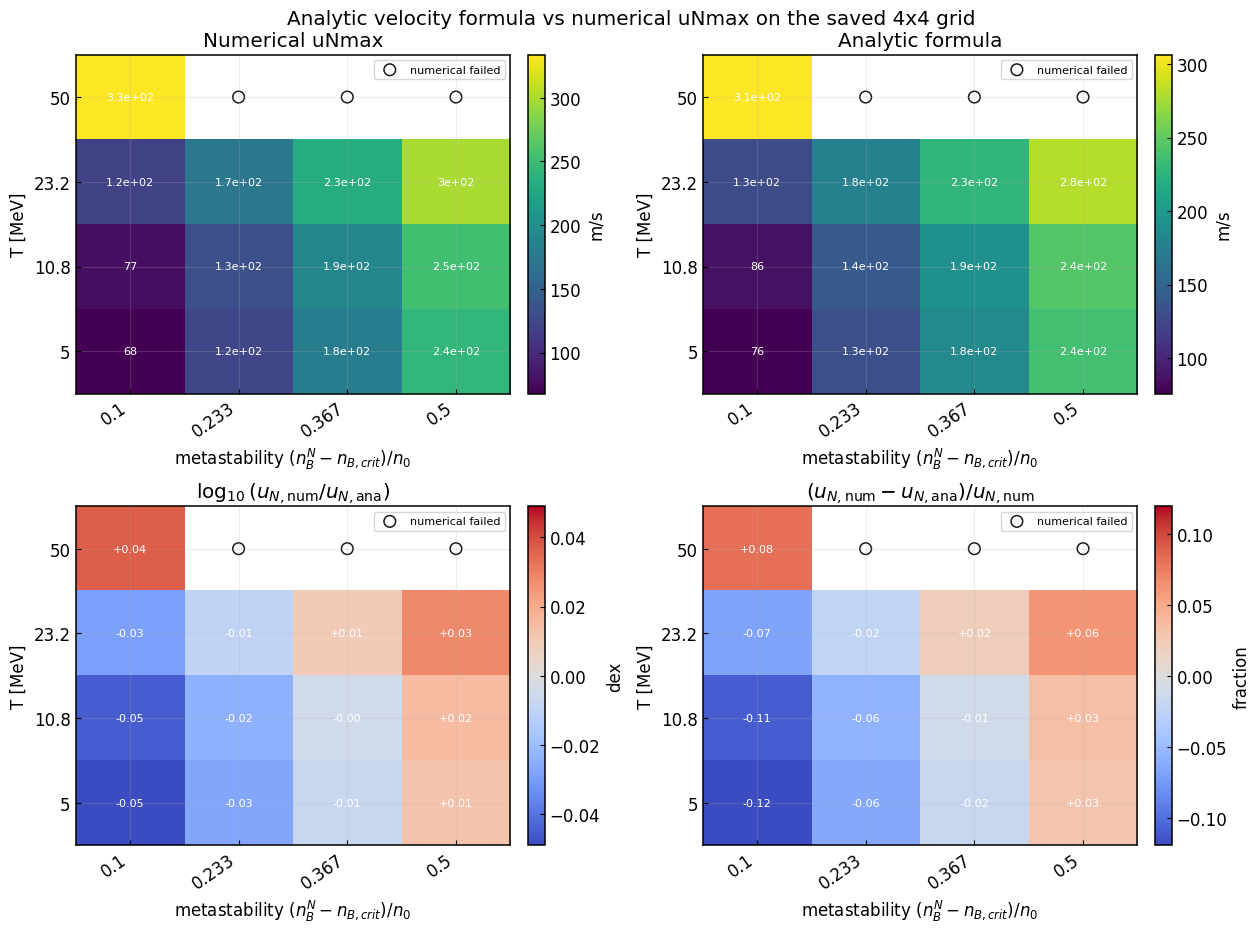

,finite_comparisons,numerical_successes,analytic_successes,ratio_min_uNmax_over_analytic,ratio_median_uNmax_over_analytic,ratio_max_uNmax_over_analytic,worst_abs_relative_delta_vs_uNmax,worst_T_MeV,worst_metastability,worst_uNmax_m_s,worst_analytic_m_s
0,13,13,13,0.89334,0.983481,1.089117,0.119395,5.0,0.1,67.602297,75.673672


,T_MeV,metastability,success,u_N_m_s,analytic_success,analytic_u_N_m_s,uNmax_over_analytic,relative_delta_vs_uNmax,analytic_aQstar_max,analytic_message
0,5.000000,0.100000,True,67.602297,True,75.673672,0.893340,-0.119395,0.237045,hydro-consistent analytic velocity bound evalu...
1,5.000000,0.233333,True,123.912024,True,131.905646,0.939399,-0.064510,0.357312,hydro-consistent analytic velocity bound evalu...
2,5.000000,0.366667,True,180.919640,True,183.958511,0.983481,-0.016797,0.447485,hydro-consistent analytic velocity bound evalu...
3,5.000000,0.500000,True,243.963576,True,237.099303,1.028951,0.028136,0.523313,hydro-consistent analytic velocity bound evalu...
4,10.772173,0.100000,True,77.327326,True,85.781857,0.901441,-0.109334,0.260759,hydro-consistent analytic velocity bound evalu...
5,10.772173,0.233333,True,132.640058,True,140.166165,0.946306,-0.056741,0.372943,hydro-consistent analytic velocity bound evalu...
6,10.772173,0.366667,True,189.775289,True,191.674644,0.990091,-0.010008,0.459681,hydro-consistent analytic velocity bound evalu...
7,10.772173,0.500000,True,253.492622,True,244.774513,1.035617,0.034392,0.533485,hydro-consistent analytic velocity bound evalu...
8,23.207944,0.100000,True,120.003396,True,128.216174,0.935946,-0.068438,0.350405,hydro-consistent analytic velocity bound evalu...
9,23.207944,0.233333,True,173.647318,True,177.534979,0.978102,-0.022388,0.438272,hydro-consistent analytic velocity bound evalu...


In [7]:
# ANALYTIC_VS_UNMAX_VISUALIZATION
# Visualize how much the hydro-consistent analytic formula disagrees with numerical uNmax.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

if "analytic_vs_unmax_df" not in globals():
    raise RuntimeError("Run ANALYTIC_VS_UNMAX_COMPARISON first.")
if analytic_vs_unmax_df.empty:
    raise RuntimeError("analytic_vs_unmax_df is empty")

comparison_df = (
    analytic_vs_unmax_df
    .dropna(subset=["T_MeV", "metastability"])
    .drop_duplicates(subset=["T_MeV", "metastability"], keep="last")
)

T_axis = np.asarray(globals().get("comparison_temperature_values", np.sort(comparison_df["T_MeV"].dropna().unique())), dtype=float)
M_axis = np.asarray(globals().get("comparison_metastability_values", np.sort(comparison_df["metastability"].dropna().unique())), dtype=float)


def _avsu_pivot(column):
    return (
        comparison_df
        .pivot_table(index="T_MeV", columns="metastability", values=column, aggfunc="last")
        .reindex(index=T_axis, columns=M_axis)
        .to_numpy(dtype=float)
    )


def _avsu_bool_pivot(column):
    if column not in comparison_df.columns:
        return np.zeros((len(T_axis), len(M_axis)), dtype=bool)
    table = (
        comparison_df
        .pivot_table(index="T_MeV", columns="metastability", values=column, aggfunc="last")
        .reindex(index=T_axis, columns=M_axis)
    )
    return table.infer_objects(copy=False).fillna(False).astype(bool).to_numpy(dtype=bool)


numeric_velocity_grid = _avsu_pivot("u_N_m_s")
analytic_velocity_grid = _avsu_pivot("analytic_u_N_m_s")
log_ratio_grid = _avsu_pivot("log10_uNmax_over_analytic")
relative_delta_grid = _avsu_pivot("relative_delta_vs_uNmax")
numeric_success_table = (
    comparison_df
    .pivot_table(index="T_MeV", columns="metastability", values="success", aggfunc="last")
    .reindex(index=T_axis, columns=M_axis)
)
missing_grid = numeric_success_table.isna().to_numpy(dtype=bool)
numeric_success_grid = numeric_success_table.infer_objects(copy=False).fillna(False).astype(bool).to_numpy(dtype=bool)
analytic_success_grid = _avsu_bool_pivot("analytic_success")
numeric_failure_grid = ~numeric_success_grid & ~missing_grid
analytic_failure_grid = numeric_success_grid & ~analytic_success_grid
finite_comparison_grid = np.isfinite(log_ratio_grid)


def _avsu_heatmap_limits(data, symmetric=False):
    finite = np.asarray(data, dtype=float)
    finite = finite[np.isfinite(finite)]
    if finite.size == 0:
        return (None, None)
    if symmetric:
        bound = float(np.nanmax(np.abs(finite)))
        if bound == 0.0:
            bound = 1.0
        return (-bound, bound)
    vmin = float(np.nanmin(finite))
    vmax = float(np.nanmax(finite))
    if np.isclose(vmin, vmax):
        pad = max(abs(vmin), 1.0) * 0.05
        return (vmin - pad, vmax + pad)
    return (vmin, vmax)


def _avsu_format_cell(value, mode):
    if not np.isfinite(value):
        return ""
    if mode == "velocity":
        return f"{value:.2g}"
    if mode == "logratio":
        return f"{value:+.2f}"
    if mode == "relative":
        return f"{value:+.2f}"
    return f"{value:.2g}"


def _avsu_plot_heatmap(ax, data, title, cbar_label, cmap="viridis", symmetric=False, mode="value"):
    vmin, vmax = _avsu_heatmap_limits(data, symmetric=symmetric)
    im = ax.imshow(data, origin="lower", aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(title)
    ax.set_xticks(np.arange(len(M_axis)))
    ax.set_xticklabels([f"{m:.3g}" for m in M_axis], rotation=35, ha="right")
    ax.set_yticks(np.arange(len(T_axis)))
    ax.set_yticklabels([f"{t:.3g}" for t in T_axis])
    ax.set_xlabel(r"metastability $(n_B^N-n_{B,crit})/n_0$")
    ax.set_ylabel("T [MeV]")
    for i in range(len(T_axis)):
        for j in range(len(M_axis)):
            text = _avsu_format_cell(data[i, j], mode)
            if text:
                ax.text(j, i, text, ha="center", va="center", fontsize=8, color="white")
    y_num, x_num = np.where(numeric_failure_grid)
    if x_num.size:
        ax.scatter(x_num, y_num, s=70, facecolors="none", edgecolors="0.1", linewidths=1.1, label="numerical failed")
    y_ana, x_ana = np.where(analytic_failure_grid)
    if x_ana.size:
        ax.scatter(x_ana, y_ana, s=55, marker="^", facecolors="none", edgecolors="tab:red", linewidths=1.1, label="analytic failed")
    y_miss, x_miss = np.where(missing_grid)
    if x_miss.size:
        ax.scatter(x_miss, y_miss, s=45, marker="x", color="0.25", linewidths=1.1, label="missing")
    if x_num.size or x_ana.size or x_miss.size:
        ax.legend(loc="best", fontsize=8, frameon=True)
    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(cbar_label)
    return im


fig, axes = plt.subplots(2, 2, figsize=(12.5, 9.0), constrained_layout=True, facecolor="white")
_avsu_plot_heatmap(axes[0, 0], numeric_velocity_grid, "Numerical uNmax", "m/s", cmap="viridis", mode="velocity")
_avsu_plot_heatmap(axes[0, 1], analytic_velocity_grid, "Analytic formula", "m/s", cmap="viridis", mode="velocity")
_avsu_plot_heatmap(axes[1, 0], log_ratio_grid, r"$\log_{10}(u_{N,\mathrm{num}}/u_{N,\mathrm{ana}})$", "dex", cmap="coolwarm", symmetric=True, mode="logratio")
_avsu_plot_heatmap(axes[1, 1], relative_delta_grid, r"$(u_{N,\mathrm{num}}-u_{N,\mathrm{ana}})/u_{N,\mathrm{num}}$", "fraction", cmap="coolwarm", symmetric=True, mode="relative")
fig.suptitle("Analytic velocity formula vs numerical uNmax on the saved 4x4 grid", y=1.02)
plt.show()

finite_rows = comparison_df[
    np.isfinite(pd.to_numeric(comparison_df["uNmax_over_analytic"], errors="coerce"))
    & np.isfinite(pd.to_numeric(comparison_df["relative_delta_vs_uNmax"], errors="coerce"))
].copy()

if finite_rows.empty:
    comparison_summary_df = pd.DataFrame([
        {
            "finite_comparisons": 0,
            "numerical_successes": int(numeric_success_grid.sum()),
            "analytic_successes": int(analytic_success_grid.sum()),
            "message": "No finite analytic/numerical comparisons are available.",
        }
    ])
else:
    finite_rows["abs_relative_delta_vs_uNmax"] = finite_rows["relative_delta_vs_uNmax"].abs()
    worst = finite_rows.sort_values("abs_relative_delta_vs_uNmax", ascending=False).iloc[0]
    ratio_values = finite_rows["uNmax_over_analytic"].to_numpy(dtype=float)
    rel_values = finite_rows["relative_delta_vs_uNmax"].to_numpy(dtype=float)
    comparison_summary_df = pd.DataFrame([
        {
            "finite_comparisons": int(len(finite_rows)),
            "numerical_successes": int(numeric_success_grid.sum()),
            "analytic_successes": int(analytic_success_grid.sum()),
            "ratio_min_uNmax_over_analytic": float(np.nanmin(ratio_values)),
            "ratio_median_uNmax_over_analytic": float(np.nanmedian(ratio_values)),
            "ratio_max_uNmax_over_analytic": float(np.nanmax(ratio_values)),
            "worst_abs_relative_delta_vs_uNmax": float(np.nanmax(np.abs(rel_values))),
            "worst_T_MeV": float(worst["T_MeV"]),
            "worst_metastability": float(worst["metastability"]),
            "worst_uNmax_m_s": float(worst["u_N_m_s"]),
            "worst_analytic_m_s": float(worst["analytic_u_N_m_s"]),
        }
    ])

display(comparison_summary_df)

comparison_display_columns = [
    "T_MeV",
    "metastability",
    "success",
    "u_N_m_s",
    "analytic_success",
    "analytic_u_N_m_s",
    "uNmax_over_analytic",
    "relative_delta_vs_uNmax",
    "analytic_aQstar_max",
    "analytic_message",
]
comparison_display_columns = [column for column in comparison_display_columns if column in comparison_df.columns]
display(comparison_df[comparison_display_columns].sort_values(["T_MeV", "metastability"]))


## Direct uNmax Contour Visualization

Visualizes the latest saved notebook-scale direct `uNmax` scan without rerunning the solver.


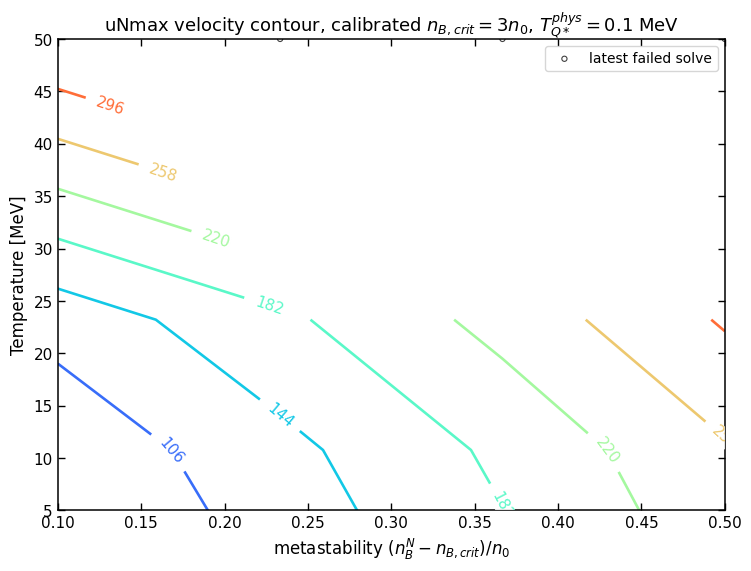

,B14_calibrated_MeV,nB_crit_over_n0,grid,TQstar_target_MeV,successes,latest_failures,missing,retried_points,total_points,u_N_min_m_s,u_N_max_m_s,contour_levels_m_s
0,189.156596,3.0,4 x 4,0.1,13,3,0,0,16,67.602297,333.803204,"67.6, 106, 144, 182, 220, 258, 296, 334"


In [8]:
# CONTOUR_VISUALIZATION

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Edit these values to choose the contour lines manually, in m/s.
# Set to None to let the plotting cell choose levels from the data range.
manual_contour_levels_m_s = None
# manual_contour_levels_m_s = [50, 100, 200, 500, 1000]
auto_contour_count = 8
contour_cmap = "rainbow"
contour_linewidth = 1.9
contour_label_fontsize = 11
axis_fontsize = 12
title_fontsize = 13
tick_fontsize = 11
legend_fontsize = 10

if "scan_pkl_path" not in globals():
    raise RuntimeError("Run the UNMAX_PARAMETER_SCAN cell first so scan_pkl_path is defined.")
if not scan_pkl_path.exists():
    raise RuntimeError(f"Run the UNMAX_PARAMETER_SCAN cell first; no saved scan data found at {scan_pkl_path}.")
scan_df = pd.read_pickle(scan_pkl_path)

latest_scan_df = (
    scan_df
    .dropna(subset=["T_MeV", "metastability"])
    .drop_duplicates(subset=["T_MeV", "metastability"], keep="last")
)

velocity_pivot = (
    latest_scan_df.pivot_table(index="T_MeV", columns="metastability", values="u_N_m_s", aggfunc="last")
    .reindex(index=temperature_values, columns=metastability_values)
)
success_pivot_raw = (
    latest_scan_df.pivot_table(index="T_MeV", columns="metastability", values="success", aggfunc="last")
    .reindex(index=temperature_values, columns=metastability_values)
)
missing_grid = success_pivot_raw.isna().to_numpy(dtype=bool)
success_grid = success_pivot_raw.fillna(False).astype(bool).to_numpy(dtype=bool)

velocity_grid = velocity_pivot.to_numpy(dtype=float)
velocity_grid[~success_grid] = np.nan

expected_shape = (len(temperature_values), len(metastability_values))
if velocity_grid.shape != expected_shape:
    raise RuntimeError(f"velocity grid shape {velocity_grid.shape} != expected {expected_shape}")

successful_velocities = velocity_grid[np.isfinite(velocity_grid)]
if successful_velocities.size == 0:
    raise RuntimeError("No successful scan points are available for contour plotting.")
if np.any(successful_velocities <= 0.0):
    raise RuntimeError("Successful scan contains non-positive velocities.")

M_grid, T_grid = np.meshgrid(metastability_values, temperature_values)
masked_velocity = np.ma.masked_invalid(velocity_grid)


def _scan_contour_levels(values, manual_levels=None, target_count=8):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values) & (values > 0.0)]
    if values.size < 2:
        raise RuntimeError("Need at least two positive finite velocities to draw contours")
    vmin = float(np.nanmin(values))
    vmax = float(np.nanmax(values))
    if np.isclose(vmin, vmax):
        raise RuntimeError("Velocity range is too narrow to draw contours")
    if manual_levels is not None:
        levels = np.asarray(manual_levels, dtype=float)
        levels = levels[np.isfinite(levels) & (levels > 0.0)]
        levels = np.unique(levels)
        levels = levels[(levels >= vmin) & (levels <= vmax)]
        if levels.size == 0:
            raise RuntimeError(f"No manual contour levels fall inside the data range [{vmin:.6g}, {vmax:.6g}] m/s")
        return levels
    if vmax / vmin >= 20.0:
        raw = np.geomspace(vmin, vmax, target_count)
    else:
        raw = np.linspace(vmin, vmax, target_count)
    return np.unique(np.asarray(raw, dtype=float))


def _scan_contour_label(value):
    value = float(value)
    if abs(value) >= 1.0e4:
        exponent = int(np.floor(np.log10(abs(value))))
        mantissa = value / (10.0 ** exponent)
        mantissa_text = f"{mantissa:.1f}".rstrip("0").rstrip(".")
        return rf"${mantissa_text}\times10^{{{exponent}}}$"
    if abs(value) >= 100.0:
        return f"{value:.0f}"
    if abs(value) >= 10.0:
        return f"{value:.1f}".rstrip("0").rstrip(".")
    return f"{value:.2g}"


fig, ax = plt.subplots(figsize=(7.4, 5.6), constrained_layout=True, facecolor="white")
ax.set_facecolor("white")
ax.grid(False)
levels = _scan_contour_levels(
    successful_velocities,
    manual_levels=manual_contour_levels_m_s,
    target_count=int(auto_contour_count),
)
contour = ax.contour(
    M_grid,
    T_grid,
    masked_velocity,
    levels=levels,
    cmap=contour_cmap,
    linewidths=float(contour_linewidth),
)
label_texts = ax.clabel(
    contour,
    contour.levels,
    inline=True,
    inline_spacing=8,
    fmt={level: _scan_contour_label(level) for level in contour.levels},
    fontsize=int(contour_label_fontsize),
)
for text in label_texts:
    text.set_bbox({"facecolor": "white", "edgecolor": "none", "alpha": 0.86, "pad": 0.8})

failure_mask = ~success_grid & ~missing_grid
if np.any(failure_mask):
    ax.scatter(
        M_grid[failure_mask],
        T_grid[failure_mask],
        s=14,
        facecolors="none",
        edgecolors="0.25",
        linewidths=0.8,
        label="latest failed solve",
    )
if np.any(missing_grid):
    ax.scatter(
        M_grid[missing_grid],
        T_grid[missing_grid],
        s=10,
        marker="x",
        color="0.35",
        linewidths=0.7,
        label="missing solve",
    )
if np.any(failure_mask) or np.any(missing_grid):
    ax.legend(loc="best", fontsize=int(legend_fontsize))

ax.set_xlabel(r"metastability $(n_B^N-n_{B,crit})/n_0$", fontsize=int(axis_fontsize))
ax.set_ylabel(r"Temperature [MeV]", fontsize=int(axis_fontsize))
title_suffix = ""
if "TQstar_target" in globals():
    title_suffix = rf", $T_{{Q*}}^{{phys}}={float(TQstar_target):g}$ MeV"
ax.set_title(r"uNmax velocity contour, calibrated $n_{B,crit}=3n_0$" + title_suffix, fontsize=int(title_fontsize))
ax.set_xlim(float(metastability_values.min()), float(metastability_values.max()))
ax.set_ylim(float(temperature_values.min()), float(temperature_values.max()))
ax.tick_params(direction="in", top=True, right=True, length=5, width=1.0, labelsize=int(tick_fontsize))
for spine in ax.spines.values():
    spine.set_linewidth(1.1)
plt.show()

point_attempt_counts = scan_df.groupby(["T_MeV", "metastability"]).size()
retried_points = int((point_attempt_counts > 1).sum())
summary_table = pd.DataFrame([
    {
        "B14_calibrated_MeV": float(B14),
        "nB_crit_over_n0": float(nB_crit / n0),
        "grid": f"{len(temperature_values)} x {len(metastability_values)}",
        "TQstar_target_MeV": float(TQstar_target),
        "successes": int(success_grid.sum()),
        "latest_failures": int(failure_mask.sum()),
        "missing": int(missing_grid.sum()),
        "retried_points": retried_points,
        "total_points": int(success_grid.size),
        "u_N_min_m_s": float(np.nanmin(velocity_grid)),
        "u_N_max_m_s": float(np.nanmax(velocity_grid)),
        "contour_levels_m_s": ", ".join(_scan_contour_label(level).replace("$", "") for level in levels),
    }
])
display(summary_table)


## Single Direct uNmax Profile Sample

Runs one direct `uNmax` solve with returned profile data for detailed inspection.


In [9]:
# SINGLE_UNMAX_SAMPLE_CALCULATION
# One sample point only: direct solver call with return_profile=True.

from pathlib import Path
import importlib
import time

import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import brentq

import RMFsolver.constants as const
import RMFsolver.RMFparameter as para
import RMFsolver.phase_velocity as phase_velocity
from RMFsolver.SQMsolver import PQM
from RMFsolver.Solver import RMFpressurePNM

phase_velocity = importlib.reload(phase_velocity)
solve_front_energy_conserving_uNmax = phase_velocity.solve_front_energy_conserving_uNmax

# Edit only this block to try a different single point.
single_T_MeV = 10.0
single_metastability = 0.0
single_TQstar_target_MeV = 0.0
single_jB_guess = 0.6
single_TQ_guess_MeV = 20.0
single_jB_bounds = (1.0e-4, 5.0)
single_B14_override_MeV = 180.0
single_tail_eps = 1.0e-4
single_n_mesh = 30
single_tol_bvp = 5.0e-2
# Rescale only the plotted compact-coordinate map x=-log(1-s)/lambda.
# Values below 1 stretch the tail in x and make the a(x) decay easier to inspect.
single_profile_lambda_scale = 0.45
single_profile_dense_points = 360

n0 = globals().get("n0", 0.16 * const.MeV_fm**3)
param = globals().get("param", para.paraQMCRMF3)
NM_type = globals().get("NM_type", "PNM")
ms = globals().get("ms", 0.0)
nB_crit = globals().get("nB_crit", 3.0 * n0)
muK_crit = globals().get("muK_crit", 0.0)


def _single_pnm_pressure_muB(mu_B, T):
    value = RMFpressurePNM(
        input_num=float(mu_B),
        input_type="muB",
        Trmf=float(T),
        para=param,
        sigma_init=30,
        w0_init=20,
        r03_init=-3,
        mub_init=max(990.0, float(mu_B)),
        verb=False,
    )
    return np.nan if value is None else float(np.asarray(value).item())


def _single_pnm_pressure_nB(n_B, T):
    value = RMFpressurePNM(
        input_num=float(n_B),
        input_type="nB",
        Trmf=float(T),
        para=param,
        sigma_init=30,
        w0_init=20,
        r03_init=-3,
        mub_init=990.0,
        verb=False,
    )
    return np.nan if value is None else float(np.asarray(value).item())


def _single_qm_pressure_muB(mu_B, T, B_one_forth):
    return float(PQM(float(mu_B), float(muK_crit), float(B_one_forth), float(T), ms=float(ms)))


def _single_safe_eval(func, x):
    try:
        value = float(func(float(x)))
    except Exception:
        return np.nan
    return value if np.isfinite(value) else np.nan


def _single_find_root_on_grid(func, x_grid, prefer=None):
    x_grid = np.asarray(x_grid, dtype=float)
    values = np.array([_single_safe_eval(func, x) for x in x_grid], dtype=float)
    finite = np.isfinite(values)
    x_grid = x_grid[finite]
    values = values[finite]
    if x_grid.size < 2:
        raise RuntimeError("Not enough finite samples to bracket a root")
    zero_hits = np.where(np.isclose(values, 0.0, atol=1.0e-8, rtol=0.0))[0]
    if zero_hits.size:
        return float(x_grid[zero_hits[0]])
    sign_changes = np.where(values[:-1] * values[1:] < 0.0)[0]
    if sign_changes.size == 0:
        raise RuntimeError("No sign change found on the requested grid")
    if prefer is None:
        idx = int(sign_changes[0])
    else:
        midpoints = 0.5 * (x_grid[sign_changes] + x_grid[sign_changes + 1])
        idx = int(sign_changes[np.argmin(np.abs(midpoints - float(prefer)))])
    return float(brentq(func, float(x_grid[idx]), float(x_grid[idx + 1]), xtol=1.0e-6, rtol=1.0e-8, maxiter=200))


def _single_solve_bag_constant_from_ncrit0(ncrit0):
    P_crit0 = _single_pnm_pressure_nB(ncrit0, 0.0)
    muB_crit0 = _single_find_root_on_grid(
        lambda mu: _single_pnm_pressure_muB(mu, 0.0) - P_crit0,
        np.linspace(900.0, 1500.0, 220),
        prefer=1050.0,
    )
    B_one_forth = _single_find_root_on_grid(
        lambda B: _single_qm_pressure_muB(muB_crit0, 0.0, B) - P_crit0,
        np.linspace(120.0, 260.0, 281),
        prefer=180.0,
    )
    return P_crit0, muB_crit0, B_one_forth


if single_B14_override_MeV is not None:
    B14 = float(single_B14_override_MeV)
elif "B14" in globals():
    B14 = float(globals()["B14"])
else:
    P_crit0, muB_crit0, B14 = _single_solve_bag_constant_from_ncrit0(nB_crit)
    print(
        "Calibrated B^(1/4) from nB_crit(T=0)=3 n0: "
        f"B14={B14:.6f} MeV, muB_crit0={muB_crit0:.6f} MeV"
    )

single_nB_N = nB_crit + float(single_metastability) * n0


single_solver_kwargs = dict(
    T=float(single_T_MeV),
    nB_N=float(single_nB_N),
    B_one_forth=float(B14),
    TQstar=float(single_TQstar_target_MeV),
    ms=float(ms),
    param=param,
    NM_type=NM_type,
    tail_eps=float(single_tail_eps),
    n_mesh=int(single_n_mesh),
    tol_bvp=float(single_tol_bvp),
    max_nodes=800,
    jB_guess=float(single_jB_guess),
    TQ_guess=float(single_TQ_guess_MeV),
    jB_bounds=single_jB_bounds,
    return_profile=True,
    verb=False,
)

print(
    "Running one uNmax sample: "
    f"T={single_T_MeV:g} MeV, metastability={single_metastability:g}, "
    f"nB_N/n0={single_nB_N / n0:.6g}, jB_guess={single_jB_guess:g}, "
    f"TQ_guess={single_TQ_guess_MeV:g} MeV, "
    f"TQstar_target={single_TQstar_target_MeV:g} MeV, "
    f"direct solve"
)

single_start_time = time.time()
try:
    single_uNmax_result = solve_front_energy_conserving_uNmax(**single_solver_kwargs)
except Exception as exc:
    single_uNmax_result = {"success": False, "message": repr(exc)}
single_elapsed_seconds = time.time() - single_start_time

single_summary = pd.DataFrame([
    {
        "success": bool(single_uNmax_result.get("success", False)),
        "message": str(single_uNmax_result.get("message", "")),
        "elapsed_seconds": single_elapsed_seconds,
        "T_MeV": float(single_T_MeV),
        "metastability": float(single_metastability),
        "nB_N_over_n0": float(single_nB_N / n0),
        "B14_used_MeV": float(B14),
        "jB": single_uNmax_result.get("jB", np.nan),
        "u_N": single_uNmax_result.get("u_N", np.nan),
        "u_N_m_s": float(single_uNmax_result.get("u_N", np.nan)) * const.m_per_sec,
        "T_Q_MeV": single_uNmax_result.get("T_Q", np.nan),
        "T_Qstar_MeV": single_uNmax_result.get("T_Qstar", np.nan),
        "aQstar": single_uNmax_result.get("aQstar", np.nan),
        "aQstar_derived": single_uNmax_result.get("aQstar_derived", np.nan),
        "profile_reconstruction_failed": single_uNmax_result.get("profile_reconstruction_failed", False),
    }
])
display(single_summary)

single_profile_keys = [
    "s_coord", "x", "nK", "jK", "a", "u", "nB", "muB", "muK",
    "T_profile", "P_profile", "h_profile", "r_gamma_profile", "invD_profile",
    "Gamma_K_profile", "jK_prime_profile", "kaon_equation_residual_profile",
]
profile_length = 0
if "x" in single_uNmax_result:
    profile_length = len(np.asarray(single_uNmax_result["x"]))

single_profile_data = {}
for key in single_profile_keys:
    if key in single_uNmax_result:
        values = np.asarray(single_uNmax_result[key], dtype=float)
        if profile_length == 0 or len(values) == profile_length:
            single_profile_data[key] = values
single_uNmax_profile_df = pd.DataFrame(single_profile_data)
if "nB" in single_uNmax_profile_df:
    single_uNmax_profile_df["nB_over_n0"] = single_uNmax_profile_df["nB"] / n0

single_muB_N = np.nan
try:
    single_muB_N = _single_find_root_on_grid(
        lambda mu: phase_velocity.nB_NM(mu, single_T_MeV, param=param, NM_type=NM_type) - single_nB_N,
        np.linspace(900.0, 1600.0, 260),
        prefer=1100.0,
    )
except Exception:
    single_muB_N = float(single_uNmax_result.get("h_over_nB_N", np.nan))

single_upstream_profile = {
    "a_N": float(single_uNmax_result.get("a_N", np.nan)),
    "u_N_m_s": float(single_uNmax_result.get("u_N", np.nan)) * const.m_per_sec,
    "nB_N_over_n0": float(single_nB_N / n0),
    "muB_N_MeV": float(single_muB_N),
    "muK_N_MeV": 0.0,
    "T_N_MeV": float(single_T_MeV),
    "T_Q_MeV": float(single_uNmax_result.get("T_Q", np.nan)),
}


def _single_build_plot_profile_df(profile_df, result, lambda_scale=1.0, dense_points=360):
    if profile_df.empty:
        return profile_df.copy()
    base = profile_df.copy().sort_values("s_coord" if "s_coord" in profile_df else profile_df.index.name or profile_df.columns[0])
    if "s_coord" in base and np.isfinite(float(result.get("lambda", np.nan))):
        s_source = base["s_coord"].to_numpy(dtype=float)
        s_dense = np.linspace(float(np.nanmin(s_source)), float(np.nanmax(s_source)), int(dense_points))
        dense = {"s_coord": s_dense}
        for col in base.columns:
            if col == "s_coord":
                continue
            values = pd.to_numeric(base[col], errors="coerce").to_numpy(dtype=float)
            finite = np.isfinite(s_source) & np.isfinite(values)
            if finite.sum() >= 2:
                dense[col] = np.interp(s_dense, s_source[finite], values[finite])
        dense_df = pd.DataFrame(dense)
        lambda_plot = float(result["lambda"]) * float(lambda_scale)
        if np.isfinite(lambda_plot) and lambda_plot > 0.0:
            s_safe = np.clip(dense_df["s_coord"].to_numpy(dtype=float), 0.0, 1.0 - np.finfo(float).eps)
            dense_df["x_plot"] = -np.log1p(-s_safe) / lambda_plot
        elif "x" in dense_df:
            dense_df["x_plot"] = dense_df["x"]
    else:
        dense_df = base.copy()
        dense_df["x_plot"] = dense_df["x"] if "x" in dense_df else np.arange(len(dense_df), dtype=float)

    if "x_plot" in dense_df:
        dense_df["x_plot_nm"] = dense_df["x_plot"] * const.MeV_fm / 1.0e6
    if "u" in dense_df:
        dense_df["u_m_s"] = dense_df["u"] * const.m_per_sec
    if "nB" in dense_df and "nB_over_n0" not in dense_df:
        dense_df["nB_over_n0"] = dense_df["nB"] / n0
    return dense_df


single_uNmax_plot_profile_df = _single_build_plot_profile_df(
    single_uNmax_profile_df,
    single_uNmax_result,
    lambda_scale=float(single_profile_lambda_scale),
    dense_points=int(single_profile_dense_points),
)

print(f"Profile columns: {list(single_uNmax_profile_df.columns)}")
print(f"Profile points: {len(single_uNmax_profile_df)}")
print(f"Plot profile points: {len(single_uNmax_plot_profile_df)}")
print(f"lambda raw={single_uNmax_result.get('lambda', np.nan):.6g}, plot lambda scale={single_profile_lambda_scale:g}")
display(single_uNmax_profile_df.head())


Running one uNmax sample: T=10 MeV, metastability=0, nB_N/n0=3, jB_guess=0.6, TQ_guess=20 MeV, TQstar_target=0 MeV, direct solve


,success,message,elapsed_seconds,T_MeV,metastability,nB_N_over_n0,B14_used_MeV,jB,u_N,u_N_m_s,T_Q_MeV,T_Qstar_MeV,aQstar,aQstar_derived,profile_reconstruction_failed
0,True,Absolute-nK uNmax BVP converged,2.351074,10.0,0.0,3.0,180.0,2.678299,7.262038e-07,217.710433,31.82403,0.0,0.550657,0.550657,False


Profile columns: ['s_coord', 'x', 'nK', 'jK', 'a', 'u', 'nB', 'muB', 'muK', 'T_profile', 'P_profile', 'h_profile', 'r_gamma_profile', 'invD_profile', 'Gamma_K_profile', 'jK_prime_profile', 'kaon_equation_residual_profile', 'nB_over_n0']
Profile points: 30
Plot profile points: 360
lambda raw=1.55426e-06, plot lambda scale=0.45


,s_coord,x,nK,jK,a,u,nB,muB,muK,T_profile,P_profile,h_profile,r_gamma_profile,invD_profile,Gamma_K_profile,jK_prime_profile,kaon_equation_residual_profile,nB_over_n0
0,0.000000,0.000000,3.065177e+06,2.673055,0.550657,4.811546e-07,5.566400e+06,1111.336176,148.838028,0.000000,6.108292e+08,6.642357e+09,1.0,0.000000,0.000002,-0.000002,0.0,4.527883
1,0.034479,22575.143405,3.065167e+06,2.632566,0.550655,4.811546e-07,5.566400e+06,1111.336201,148.837510,0.082928,6.108292e+08,6.642357e+09,1.0,0.000502,0.000002,-0.000002,0.0,4.527883
2,0.068959,45971.292285,3.065102e+06,2.590604,0.550643,4.811546e-07,5.566400e+06,1111.336365,148.834033,0.230110,6.108292e+08,6.642357e+09,1.0,0.002850,0.000002,-0.000002,0.0,4.527883
3,0.103438,70250.423812,3.064873e+06,2.547058,0.550602,4.811546e-07,5.566400e+06,1111.336938,148.821875,0.462702,6.108292e+08,6.642357e+09,1.0,0.009411,0.000002,-0.000002,0.0,4.527883
4,0.137917,95481.809297,3.064278e+06,2.501802,0.550496,4.811546e-07,5.566400e+06,1111.338427,148.790300,0.795305,6.108292e+08,6.642357e+09,1.0,0.023873,0.000002,-0.000002,0.0,4.527883


## Single Profile Visualization

Plots the returned single-solve profile fields and residual diagnostics.


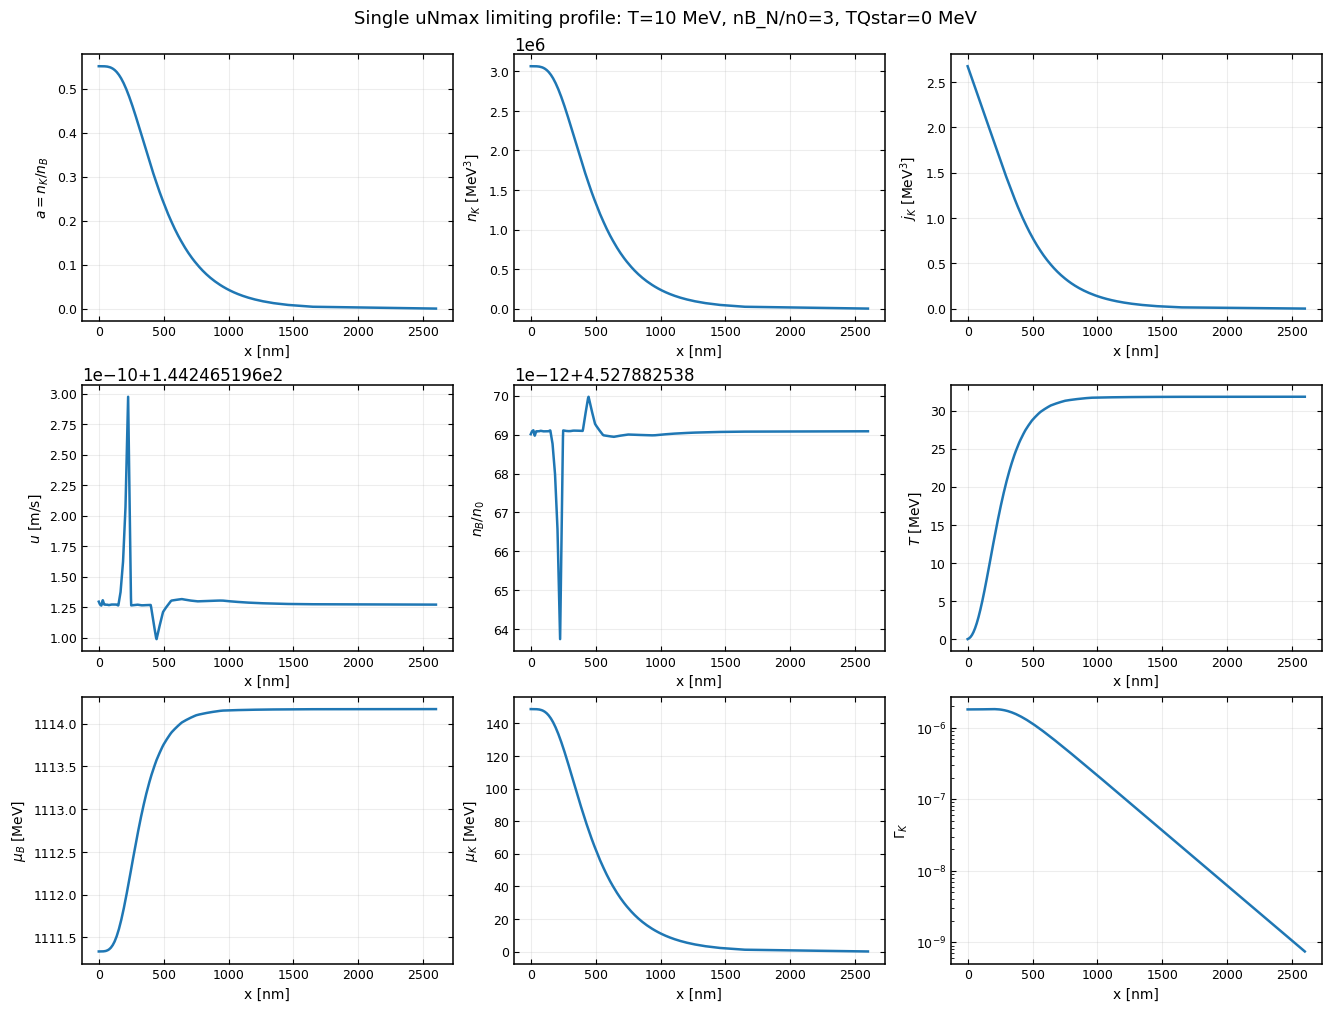

In [10]:
# SINGLE_UNMAX_PROFILE_VISUALIZATION
# Tunable plotting parameters
FIGURE_SIZE = (13.2, 10.0)
SUBPLOT_ROWS = 3
SUBPLOT_COLUMNS = 3
CONSTRAINED_LAYOUT = True
FIGURE_FACE_COLOR = "white"
AXES_FACE_COLOR = "white"
GRID_ENABLED = True
GRID_ALPHA = 0.22
LINE_COLOR = "C0"
LINE_STYLE = "-"
LINE_WIDTH = 1.8
LINE_ALPHA = 1.0
TITLE_FONT_SIZE = 13
AXIS_LABEL_FONT_SIZE = 10
TICK_LABEL_FONT_SIZE = 9
TICK_DIRECTION = "in"
SHOW_TOP_TICKS = True
SHOW_RIGHT_TICKS = True
MISSING_TEXT_POSITION = (0.5, 0.5)
MISSING_TEXT_ALIGNMENT = "center"
PLOT_SPECS = [
    ("a", r"$a=n_K/n_B$", "linear"),
    ("nK", r"$n_K$ [MeV$^3$]", "linear"),
    ("jK", r"$j_K$ [MeV$^3$]", "linear"),
    ("u_m_s", r"$u$ [m/s]", "linear"),
    ("nB_over_n0", r"$n_B/n_0$", "linear"),
    ("T_profile", r"$T$ [MeV]", "linear"),
    ("muB", r"$\mu_B$ [MeV]", "linear"),
    ("muK", r"$\mu_K$ [MeV]", "linear"),
    ("Gamma_K_profile", r"$\Gamma_K$", "log"),
]

import matplotlib.pyplot as plt

if "single_uNmax_plot_profile_df" not in globals() or single_uNmax_plot_profile_df.empty:
    raise RuntimeError("Run SINGLE_UNMAX_SAMPLE_CALCULATION first and make sure it returned a profile.")

profile_df = single_uNmax_plot_profile_df.copy()
x_col = "x_plot_nm" if "x_plot_nm" in profile_df else ("x_plot" if "x_plot" in profile_df else "x")
x_values = profile_df[x_col].to_numpy(dtype=float)
x_label = "x [nm]" if x_col == "x_plot_nm" else "x [MeV$^{-1}$]"

fig, axes = plt.subplots(
    SUBPLOT_ROWS,
    SUBPLOT_COLUMNS,
    figsize=FIGURE_SIZE,
    constrained_layout=CONSTRAINED_LAYOUT,
    facecolor=FIGURE_FACE_COLOR,
)
axes = axes.ravel()

for ax, (col, ylabel, scale) in zip(axes, PLOT_SPECS):
    ax.set_facecolor(AXES_FACE_COLOR)
    ax.grid(GRID_ENABLED, alpha=GRID_ALPHA)
    if col not in profile_df:
        ax.text(
            *MISSING_TEXT_POSITION,
            f"missing {col}",
            ha=MISSING_TEXT_ALIGNMENT,
            va=MISSING_TEXT_ALIGNMENT,
            transform=ax.transAxes,
        )
        ax.set_axis_off()
        continue
    y_values = pd.to_numeric(profile_df[col], errors="coerce").to_numpy(dtype=float)
    finite = np.isfinite(x_values) & np.isfinite(y_values)
    if scale == "log":
        finite &= y_values > 0.0
        ax.set_yscale("log")
    if finite.any():
        ax.plot(
            x_values[finite],
            y_values[finite],
            color=LINE_COLOR,
            linestyle=LINE_STYLE,
            linewidth=LINE_WIDTH,
            alpha=LINE_ALPHA,
        )
    ax.set_xlabel(x_label, fontsize=AXIS_LABEL_FONT_SIZE)
    ax.set_ylabel(ylabel, fontsize=AXIS_LABEL_FONT_SIZE)
    ax.tick_params(
        labelsize=TICK_LABEL_FONT_SIZE,
        direction=TICK_DIRECTION,
        top=SHOW_TOP_TICKS,
        right=SHOW_RIGHT_TICKS,
    )

fig.suptitle(
    "Single uNmax limiting profile: "
    f"T={single_T_MeV:g} MeV, nB_N/n0={single_nB_N / n0:.4g}, "
    f"TQstar={single_TQstar_target_MeV:g} MeV",
    fontsize=TITLE_FONT_SIZE,
)
plt.show()


## Imported 1Jun Cluster Payload

Loads the newest downloaded 1Jun cluster mirror payload and visualizes the numerical velocity grid, derived `aQstar` grid, convergence coverage, and saved boundary cut. The dashboard figure is also saved under `new_paper_calculations/26-06-01/figures/`.


,payload_path,run_tag,closure,boundary_closure,TQstar_target_MeV,B14_MeV,nB_crit_over_n0,temperature_points,metastability_points,records,successes,failures,finite_aQstar_points,finite_boundary_points,u_N_m_s_min,u_N_m_s_max,aQstar_min,aQstar_max
0,new_paper_calculations/26-06-01/26SU-2-hydro-numer...,numerical_uNmax_v1,uNmax_direct_TQstar,hydro_jump_eigenvalue_aQstar_max_1,0.5,189.156596,3.0,150,35,5250,1877,3373,1877,35,33.242062,709.413516,0.150299,0.825369


,metastability,temperature_cut_MeV,temperature_lower_bracket_MeV,temperature_upper_bracket_MeV,status,success,aQstar_min,aQstar_max
0,0.010000,89.363403,89.363403,89.366113,bracketed,True,0.072571,0.999990
1,0.036176,88.932520,88.932520,88.935229,bracketed,True,0.138132,0.999982
2,0.062353,88.493506,88.493506,88.496216,bracketed,True,0.181493,0.999987
3,0.088529,88.043652,88.043652,88.046362,bracketed,True,0.216434,0.999980
4,0.114706,87.585669,87.585669,87.588379,bracketed,True,0.246560,0.999988
5,0.140882,87.116846,87.116846,87.119556,bracketed,True,0.273465,0.999988
6,0.167059,86.637183,86.637183,86.639893,bracketed,True,0.298023,0.999981
7,0.193235,86.149390,86.149390,86.152100,bracketed,True,0.320772,0.999996
8,0.219412,85.648047,85.648047,85.650757,bracketed,True,0.342072,0.999982
9,0.245588,85.138574,85.138574,85.141284,bracketed,True,0.362180,0.999994


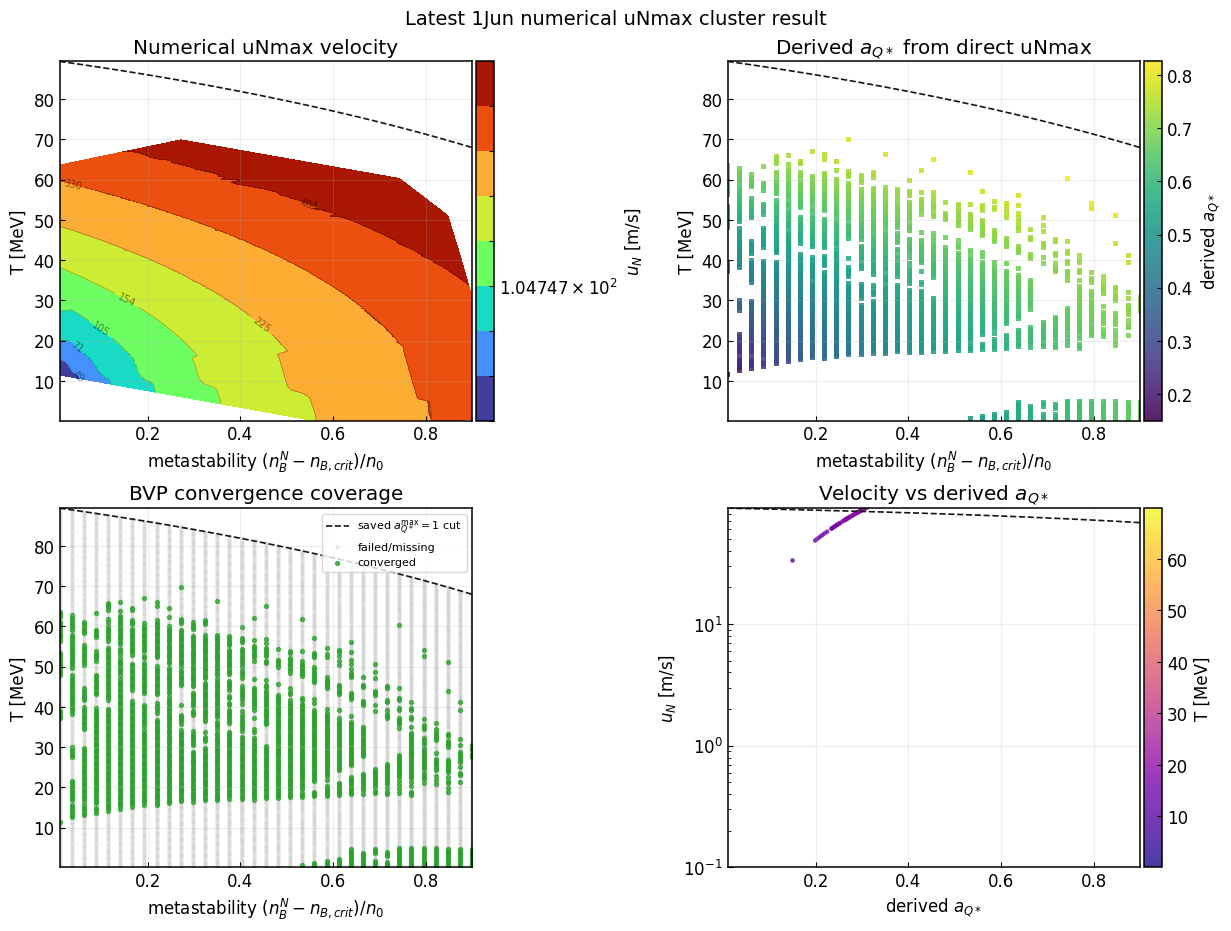

Saved dashboard figure to new_paper_calculations/26-06-01/figures/latest_cluster_uNmax_dashboard.png


In [11]:
# CLUSTER_1JUN_UNMAX_VISUALIZATION
# Filesystem-only visualization of the latest downloaded 1Jun numerical-uNmax cluster payload.

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import display

cluster_1jun_dir = Path("new_paper_calculations/26-06-01")
cluster_1jun_pattern = "26SU-2-hydro-numerical-uNmax-adaptive-contour__*.npy"
cluster_1jun_candidates = sorted(cluster_1jun_dir.glob(cluster_1jun_pattern))
if not cluster_1jun_candidates:
    raise FileNotFoundError(f"No cluster payload matched {cluster_1jun_dir / cluster_1jun_pattern}")

cluster_1jun_payload_path = max(cluster_1jun_candidates, key=lambda path: path.stat().st_mtime)
cluster_1jun_payload = np.load(cluster_1jun_payload_path, allow_pickle=True).item()
cluster_1jun_figure_dir = cluster_1jun_dir / "figures"
cluster_1jun_figure_dir.mkdir(parents=True, exist_ok=True)

cluster_1jun_temperature_values = np.asarray(cluster_1jun_payload.get("temperature_values", []), dtype=float)
cluster_1jun_metastability_values = np.asarray(cluster_1jun_payload.get("metastability_values", []), dtype=float)
cluster_1jun_boundary_temperature_values = np.asarray(cluster_1jun_payload.get("boundary_temperature_values", []), dtype=float)
cluster_1jun_boundary_metastability_values = np.asarray(cluster_1jun_payload.get("boundary_metastability_values", []), dtype=float)
cluster_1jun_velocity_grid = np.asarray(cluster_1jun_payload.get("velocity_grid_m_s", []), dtype=float)
cluster_1jun_u_N_grid = np.asarray(cluster_1jun_payload.get("u_N_grid", []), dtype=float)
cluster_1jun_aQstar_grid = np.asarray(cluster_1jun_payload.get("aQstar_grid", []), dtype=float)
cluster_1jun_temperature_grid = np.asarray(cluster_1jun_payload.get("temperature_grid", []), dtype=float)
cluster_1jun_metastability_grid = np.asarray(cluster_1jun_payload.get("metastability_grid", []), dtype=float)
cluster_1jun_records = pd.DataFrame.from_records(list(cluster_1jun_payload.get("records", [])))
cluster_1jun_boundary_records = pd.DataFrame.from_records(list(cluster_1jun_payload.get("boundary_records", [])))

if (
    cluster_1jun_temperature_grid.shape == cluster_1jun_velocity_grid.shape
    and cluster_1jun_metastability_grid.shape == cluster_1jun_velocity_grid.shape
    and np.isfinite(cluster_1jun_temperature_grid).any()
):
    cluster_1jun_M_grid = cluster_1jun_metastability_grid
    cluster_1jun_T_grid = cluster_1jun_temperature_grid
elif cluster_1jun_metastability_values.size and cluster_1jun_temperature_values.size:
    cluster_1jun_M_grid, cluster_1jun_T_grid = np.meshgrid(
        cluster_1jun_metastability_values,
        cluster_1jun_temperature_values,
    )
else:
    cluster_1jun_M_grid = np.full_like(cluster_1jun_velocity_grid, np.nan, dtype=float)
    cluster_1jun_T_grid = np.full_like(cluster_1jun_velocity_grid, np.nan, dtype=float)

cluster_1jun_finite_velocity = np.isfinite(cluster_1jun_velocity_grid) & (cluster_1jun_velocity_grid > 0.0)
cluster_1jun_finite_aq = np.isfinite(cluster_1jun_aQstar_grid)
cluster_1jun_finite_boundary = np.isfinite(cluster_1jun_boundary_metastability_values) & np.isfinite(cluster_1jun_boundary_temperature_values)
cluster_1jun_boundary_order = np.argsort(cluster_1jun_boundary_metastability_values[cluster_1jun_finite_boundary]) if np.any(cluster_1jun_finite_boundary) else np.array([], dtype=int)
cluster_1jun_boundary_m_plot = cluster_1jun_boundary_metastability_values[cluster_1jun_finite_boundary][cluster_1jun_boundary_order] if np.any(cluster_1jun_finite_boundary) else np.array([], dtype=float)
cluster_1jun_boundary_T_plot = cluster_1jun_boundary_temperature_values[cluster_1jun_finite_boundary][cluster_1jun_boundary_order] if np.any(cluster_1jun_finite_boundary) else np.array([], dtype=float)

cluster_1jun_success_count = int(cluster_1jun_finite_velocity.sum())
cluster_1jun_total_records = int(len(cluster_1jun_records))
cluster_1jun_failure_count = int(cluster_1jun_total_records - cluster_1jun_success_count) if cluster_1jun_total_records else int(cluster_1jun_velocity_grid.size - cluster_1jun_success_count)
cluster_1jun_summary = pd.DataFrame([
    {
        "payload_path": str(cluster_1jun_payload_path),
        "run_tag": cluster_1jun_payload.get("run_tag", ""),
        "closure": cluster_1jun_payload.get("analytic_closure", ""),
        "boundary_closure": cluster_1jun_payload.get("boundary_closure", ""),
        "TQstar_target_MeV": float(cluster_1jun_payload.get("TQstar_target_MeV", np.nan)),
        "B14_MeV": float(cluster_1jun_payload.get("B14", np.nan)),
        "nB_crit_over_n0": float(cluster_1jun_payload.get("nB_crit", np.nan) / cluster_1jun_payload.get("n0", np.nan)),
        "temperature_points": int(cluster_1jun_temperature_values.size),
        "metastability_points": int(cluster_1jun_metastability_values.size),
        "records": cluster_1jun_total_records,
        "successes": cluster_1jun_success_count,
        "failures": cluster_1jun_failure_count,
        "finite_aQstar_points": int(cluster_1jun_finite_aq.sum()),
        "finite_boundary_points": int(cluster_1jun_finite_boundary.sum()),
        "u_N_m_s_min": float(np.nanmin(cluster_1jun_velocity_grid[cluster_1jun_finite_velocity])) if np.any(cluster_1jun_finite_velocity) else np.nan,
        "u_N_m_s_max": float(np.nanmax(cluster_1jun_velocity_grid[cluster_1jun_finite_velocity])) if np.any(cluster_1jun_finite_velocity) else np.nan,
        "aQstar_min": float(np.nanmin(cluster_1jun_aQstar_grid[cluster_1jun_finite_aq])) if np.any(cluster_1jun_finite_aq) else np.nan,
        "aQstar_max": float(np.nanmax(cluster_1jun_aQstar_grid[cluster_1jun_finite_aq])) if np.any(cluster_1jun_finite_aq) else np.nan,
    }
])
display(cluster_1jun_summary)

if not cluster_1jun_boundary_records.empty:
    boundary_display_columns = [
        "metastability",
        "temperature_cut_MeV",
        "temperature_lower_bracket_MeV",
        "temperature_upper_bracket_MeV",
        "status",
        "success",
        "aQstar_min",
        "aQstar_max",
    ]
    boundary_display_columns = [column for column in boundary_display_columns if column in cluster_1jun_boundary_records.columns]
    display(cluster_1jun_boundary_records[boundary_display_columns].sort_values("metastability").reset_index(drop=True))

finite_x = cluster_1jun_M_grid[np.isfinite(cluster_1jun_M_grid)]
finite_y = cluster_1jun_T_grid[np.isfinite(cluster_1jun_T_grid)]
x_min = float(np.nanmin(finite_x)) if finite_x.size else 0.0
x_max = float(np.nanmax(finite_x)) if finite_x.size else 1.0
y_min = float(np.nanmin(finite_y)) if finite_y.size else 0.0
y_max = float(np.nanmax(finite_y)) if finite_y.size else 100.0

fig, axes = plt.subplots(2, 2, figsize=(12.2, 9.2), constrained_layout=True, facecolor="white")
for ax in axes.ravel():
    ax.set_facecolor("white")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel(r"metastability $(n_B^N-n_{B,crit})/n_0$")
    ax.set_ylabel("T [MeV]")
    ax.grid(alpha=0.22)
    if cluster_1jun_boundary_m_plot.size:
        ax.plot(cluster_1jun_boundary_m_plot, cluster_1jun_boundary_T_plot, color="0.08", lw=1.2, ls="--", label=r"saved $a_{Q*}^{\rm max}=1$ cut")

ax = axes[0, 0]
if np.any(cluster_1jun_finite_velocity):
    velocity_values = cluster_1jun_velocity_grid[cluster_1jun_finite_velocity]
    levels = np.geomspace(float(np.nanmin(velocity_values)), float(np.nanmax(velocity_values)), 9)
    contour = ax.tricontourf(
        cluster_1jun_M_grid[cluster_1jun_finite_velocity],
        cluster_1jun_T_grid[cluster_1jun_finite_velocity],
        velocity_values,
        levels=np.unique(levels),
        cmap="turbo",
        norm=LogNorm(vmin=float(np.nanmin(velocity_values)), vmax=float(np.nanmax(velocity_values))),
    )
    line_contour = ax.tricontour(
        cluster_1jun_M_grid[cluster_1jun_finite_velocity],
        cluster_1jun_T_grid[cluster_1jun_finite_velocity],
        velocity_values,
        levels=np.unique(levels[1:-1]),
        colors="k",
        linewidths=0.35,
        alpha=0.45,
    )
    ax.clabel(line_contour, fmt=lambda value: f"{value:.0f}", fontsize=7)
    cbar = fig.colorbar(contour, ax=ax, pad=0.01)
    cbar.set_label(r"$u_N$ [m/s]")
else:
    ax.text(0.5, 0.5, "no finite velocity points", transform=ax.transAxes, ha="center", va="center", color="0.35")
ax.set_title("Numerical uNmax velocity")

ax = axes[0, 1]
if np.any(cluster_1jun_finite_aq):
    aq_values = cluster_1jun_aQstar_grid[cluster_1jun_finite_aq]
    scatter = ax.scatter(
        cluster_1jun_M_grid[cluster_1jun_finite_aq],
        cluster_1jun_T_grid[cluster_1jun_finite_aq],
        c=aq_values,
        s=13,
        marker="s",
        cmap="viridis",
        linewidths=0.0,
        alpha=0.88,
    )
    cbar = fig.colorbar(scatter, ax=ax, pad=0.01)
    cbar.set_label(r"derived $a_{Q*}$")
else:
    ax.text(0.5, 0.5, "no finite aQstar points", transform=ax.transAxes, ha="center", va="center", color="0.35")
ax.set_title(r"Derived $a_{Q*}$ from direct uNmax")

ax = axes[1, 0]
finite_grid_points = np.isfinite(cluster_1jun_M_grid) & np.isfinite(cluster_1jun_T_grid)
failed_points = finite_grid_points & ~cluster_1jun_finite_velocity
if np.any(failed_points):
    ax.scatter(cluster_1jun_M_grid[failed_points], cluster_1jun_T_grid[failed_points], s=5, color="0.75", alpha=0.28, label="failed/missing")
if np.any(cluster_1jun_finite_velocity):
    ax.scatter(cluster_1jun_M_grid[cluster_1jun_finite_velocity], cluster_1jun_T_grid[cluster_1jun_finite_velocity], s=8, color="tab:green", alpha=0.78, label="converged")
ax.set_title("BVP convergence coverage")
ax.legend(loc="best", fontsize=8, frameon=True)

ax = axes[1, 1]
if np.any(cluster_1jun_finite_velocity):
    ax.scatter(
        cluster_1jun_aQstar_grid[cluster_1jun_finite_velocity],
        cluster_1jun_velocity_grid[cluster_1jun_finite_velocity],
        c=cluster_1jun_T_grid[cluster_1jun_finite_velocity],
        s=11,
        cmap="plasma",
        alpha=0.78,
        linewidths=0.0,
    )
    ax.set_xlabel(r"derived $a_{Q*}$")
    ax.set_ylabel(r"$u_N$ [m/s]")
    ax.set_yscale("log")
    ax.grid(alpha=0.22)
    cbar = fig.colorbar(ax.collections[-1], ax=ax, pad=0.01)
    cbar.set_label("T [MeV]")
else:
    ax.text(0.5, 0.5, "no finite velocity/aQstar pairs", transform=ax.transAxes, ha="center", va="center", color="0.35")
ax.set_title(r"Velocity vs derived $a_{Q*}$")

fig.suptitle("Latest 1Jun numerical uNmax cluster result", fontsize=14)
cluster_1jun_dashboard_path = cluster_1jun_figure_dir / "latest_cluster_uNmax_dashboard.png"
fig.savefig(cluster_1jun_dashboard_path, dpi=180)
plt.show()
print(f"Saved dashboard figure to {cluster_1jun_dashboard_path}")


<!-- LATEST_1JUN_CLUSTER_DASHBOARD_SNAPSHOT -->
## Latest 1Jun Cluster Dashboard Snapshot

Static quicklook generated from the newest payload in `new_paper_calculations/26-06-01/`. Rerun the preceding cluster visualization cell to refresh this image after downloading a newer payload.

![Latest 1Jun numerical uNmax dashboard](new_paper_calculations/26-06-01/figures/latest_cluster_uNmax_dashboard.png)


## Cluster Boundary vs Local Analytic Overlay

Overlays the cluster boundary-stage `aQstar_max` samples with the latest local analytic `aQstar_max = 1` line.


In [ ]:
# CLUSTER_AQSTAR_ANALYTIC_BOUNDARY_OVERLAY
# Overlay the newest saved analytic aQstar_max=1 boundary on the downloaded 1Jun cluster aQstar_max samples.

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

if "cluster_1jun_payload" not in globals():
    cluster_1jun_dir = Path("new_paper_calculations/26-06-01")
    cluster_1jun_pattern = "26SU-2-hydro-numerical-uNmax-adaptive-contour__*.npy"
    cluster_1jun_candidates = sorted(cluster_1jun_dir.glob(cluster_1jun_pattern))
    if not cluster_1jun_candidates:
        raise FileNotFoundError(f"No cluster payload matched {cluster_1jun_dir / cluster_1jun_pattern}")
    cluster_1jun_payload_path = max(cluster_1jun_candidates, key=lambda path: path.stat().st_mtime)
    cluster_1jun_payload = np.load(cluster_1jun_payload_path, allow_pickle=True).item()
    cluster_1jun_temperature_values = np.asarray(cluster_1jun_payload.get("temperature_values", []), dtype=float)
    cluster_1jun_metastability_values = np.asarray(cluster_1jun_payload.get("metastability_values", []), dtype=float)
    cluster_1jun_boundary_temperature_values = np.asarray(cluster_1jun_payload.get("boundary_temperature_values", []), dtype=float)
    cluster_1jun_boundary_metastability_values = np.asarray(cluster_1jun_payload.get("boundary_metastability_values", []), dtype=float)
    cluster_1jun_aQstar_grid = np.asarray(cluster_1jun_payload.get("aQstar_grid", []), dtype=float)
    cluster_1jun_temperature_grid = np.asarray(cluster_1jun_payload.get("temperature_grid", []), dtype=float)
    cluster_1jun_metastability_grid = np.asarray(cluster_1jun_payload.get("metastability_grid", []), dtype=float)
    cluster_1jun_records = pd.DataFrame.from_records(list(cluster_1jun_payload.get("records", [])))
    cluster_1jun_boundary_records = pd.DataFrame.from_records(list(cluster_1jun_payload.get("boundary_records", [])))

analytic_boundary_patterns = [
    Path(".").glob("26SU-2-hydro-analytic-adaptive-contour__*.npy"),
    Path(".").glob("26SU-2-hydro-analytic-velocity-contour*.npy"),
    Path("local_analysis_results/22May").rglob("*.npy"),
    Path("new_paper_calculations/26-06-01").glob("*analytic*.npy"),
]
analytic_boundary_candidates = []
for pattern in analytic_boundary_patterns:
    for candidate_path in pattern:
        if not candidate_path.exists():
            continue
        try:
            candidate_payload = np.load(candidate_path, allow_pickle=True).item()
        except Exception:
            continue
        candidate_m = np.asarray(candidate_payload.get("boundary_metastability_values", []), dtype=float)
        candidate_T = np.asarray(candidate_payload.get("boundary_temperature_values", []), dtype=float)
        finite_candidate = np.isfinite(candidate_m) & np.isfinite(candidate_T)
        if candidate_m.size and candidate_T.size and candidate_m.shape == candidate_T.shape and np.any(finite_candidate):
            analytic_boundary_candidates.append((candidate_path, candidate_payload, int(np.sum(finite_candidate))))

if not analytic_boundary_candidates:
    raise FileNotFoundError("No analytic payload with finite boundary_metastability_values/boundary_temperature_values was found.")

analytic_boundary_path, analytic_boundary_payload, analytic_boundary_finite_count = max(
    analytic_boundary_candidates,
    key=lambda item: item[0].stat().st_mtime,
)
analytic_boundary_m = np.asarray(analytic_boundary_payload["boundary_metastability_values"], dtype=float)
analytic_boundary_T = np.asarray(analytic_boundary_payload["boundary_temperature_values"], dtype=float)
finite_analytic_boundary = np.isfinite(analytic_boundary_m) & np.isfinite(analytic_boundary_T)
analytic_order = np.argsort(analytic_boundary_m[finite_analytic_boundary])
analytic_plot_m = analytic_boundary_m[finite_analytic_boundary][analytic_order]
analytic_plot_T = analytic_boundary_T[finite_analytic_boundary][analytic_order]

cluster_boundary_records_raw = list(cluster_1jun_payload.get("boundary_records", []))
cluster_eval_rows = []
for boundary_record in cluster_boundary_records_raw:
    record_m = boundary_record.get("metastability", np.nan)
    for evaluation in boundary_record.get("evaluations", []):
        cluster_eval_rows.append(
            {
                "metastability": float(evaluation.get("metastability", record_m)),
                "T_MeV": float(evaluation.get("T_MeV", np.nan)),
                "aQstar_max": float(evaluation.get("aQstar_max", np.nan)),
                "success": bool(evaluation.get("success", False)),
                "stage": str(evaluation.get("boundary_stage", "")),
                "message": str(evaluation.get("message", "")),
            }
        )

cluster_eval_df = pd.DataFrame(cluster_eval_rows)
if cluster_eval_df.empty:
    fallback_records = []
    for boundary_record in cluster_boundary_records_raw:
        fallback_records.append(
            {
                "metastability": float(boundary_record.get("metastability", np.nan)),
                "T_MeV": float(boundary_record.get("temperature_cut_MeV", np.nan)),
                "aQstar_max": float(boundary_record.get("aQstar_max", np.nan)),
                "success": bool(boundary_record.get("success", False)),
                "stage": "boundary_cut",
                "message": str(boundary_record.get("status", "")),
            }
        )
    cluster_eval_df = pd.DataFrame(fallback_records)

for column in ["metastability", "T_MeV", "aQstar_max"]:
    if column in cluster_eval_df.columns:
        cluster_eval_df[column] = pd.to_numeric(cluster_eval_df[column], errors="coerce")
cluster_eval_finite = (
    np.isfinite(cluster_eval_df["metastability"].to_numpy(dtype=float))
    & np.isfinite(cluster_eval_df["T_MeV"].to_numpy(dtype=float))
    & np.isfinite(cluster_eval_df["aQstar_max"].to_numpy(dtype=float))
)
cluster_eval_plot_df = cluster_eval_df.loc[cluster_eval_finite].copy()

cluster_boundary_m = np.asarray(cluster_1jun_boundary_metastability_values, dtype=float)
cluster_boundary_T = np.asarray(cluster_1jun_boundary_temperature_values, dtype=float)
finite_cluster_boundary = np.isfinite(cluster_boundary_m) & np.isfinite(cluster_boundary_T)
cluster_boundary_order = np.argsort(cluster_boundary_m[finite_cluster_boundary]) if np.any(finite_cluster_boundary) else np.array([], dtype=int)
cluster_plot_m = cluster_boundary_m[finite_cluster_boundary][cluster_boundary_order] if np.any(finite_cluster_boundary) else np.array([], dtype=float)
cluster_plot_T = cluster_boundary_T[finite_cluster_boundary][cluster_boundary_order] if np.any(finite_cluster_boundary) else np.array([], dtype=float)

cluster_aq_grid = np.asarray(cluster_1jun_aQstar_grid, dtype=float)
finite_cluster_aq_grid = np.isfinite(cluster_aq_grid)

summary_rows = [
    {
        "cluster_payload_path": str(cluster_1jun_payload_path),
        "analytic_boundary_path": str(analytic_boundary_path),
        "analytic_boundary_points": int(analytic_boundary_finite_count),
        "cluster_boundary_points": int(np.sum(finite_cluster_boundary)),
        "cluster_boundary_evaluations": int(len(cluster_eval_df)),
        "finite_cluster_boundary_aQstar_evaluations": int(len(cluster_eval_plot_df)),
        "finite_velocity_stage_aQstar_grid_points": int(np.sum(finite_cluster_aq_grid)),
        "cluster_velocity_records": int(len(cluster_1jun_payload.get("records", []))),
        "cluster_TQstar_target_MeV": float(cluster_1jun_payload.get("TQstar_target_MeV", np.nan)),
    }
]
display(pd.DataFrame(summary_rows))

fig, ax = plt.subplots(figsize=(8.4, 6.0), constrained_layout=True, facecolor="white")
ax.set_facecolor("white")

if not cluster_eval_plot_df.empty:
    color_values = cluster_eval_plot_df["aQstar_max"].to_numpy(dtype=float)
    vmin = float(np.nanmin(color_values))
    vmax = float(np.nanmax(color_values))
    if np.isclose(vmin, vmax):
        vmin = max(0.0, vmin - 0.05)
        vmax = vmax + 0.05
    scatter = ax.scatter(
        cluster_eval_plot_df["metastability"],
        cluster_eval_plot_df["T_MeV"],
        c=color_values,
        s=14,
        marker="s",
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        linewidths=0.0,
        alpha=0.58,
        zorder=1,
        label=r"1Jun boundary evaluations: $a_{Q*}^{\rm max}$",
    )
    cbar = fig.colorbar(scatter, ax=ax, pad=0.015)
    cbar.set_label(r"cluster $a_{Q*}^{\rm max}$")
    if np.nanmin(color_values) < 1.0 < np.nanmax(color_values):
        try:
            contour = ax.tricontour(
                cluster_eval_plot_df["metastability"].to_numpy(dtype=float),
                cluster_eval_plot_df["T_MeV"].to_numpy(dtype=float),
                color_values,
                levels=[1.0],
                colors=["tab:blue"],
                linestyles=[":"],
                linewidths=1.2,
            )
            contour.collections[0].set_label(r"cluster interpolated $a_{Q*}^{\rm max}=1$")
        except Exception as exc:
            print(f"Could not draw cluster aQstar_max=1 tricontour: {exc}")
else:
    ax.text(
        0.5,
        0.5,
        "cluster payload has no finite boundary aQstar_max evaluations",
        transform=ax.transAxes,
        ha="center",
        va="center",
        color="0.35",
    )

if cluster_plot_m.size:
    ax.plot(
        cluster_plot_m,
        cluster_plot_T,
        color="0.10",
        lw=1.25,
        ls="--",
        marker="^",
        markersize=4.2,
        markerfacecolor="white",
        markeredgewidth=0.9,
        label=r"1Jun boundary cut",
    )
if analytic_plot_m.size:
    ax.plot(
        analytic_plot_m,
        analytic_plot_T,
        color="tab:red",
        lw=1.45,
        marker="x",
        markersize=5.0,
        markeredgewidth=1.1,
        label=r"latest analytic $a_{Q*}^{\rm max}=1$",
    )
    ax.scatter(analytic_plot_m, analytic_plot_T, s=34, marker="x", color="tab:red", linewidths=1.1, zorder=5)

x_sources = [analytic_plot_m, cluster_plot_m]
y_sources = [analytic_plot_T, cluster_plot_T]
if not cluster_eval_plot_df.empty:
    x_sources.append(cluster_eval_plot_df["metastability"].to_numpy(dtype=float))
    y_sources.append(cluster_eval_plot_df["T_MeV"].to_numpy(dtype=float))
x_all = np.concatenate([arr[np.isfinite(arr)] for arr in x_sources if np.asarray(arr).size])
y_all = np.concatenate([arr[np.isfinite(arr)] for arr in y_sources if np.asarray(arr).size])
if x_all.size:
    ax.set_xlim(float(np.nanmin(x_all)), float(np.nanmax(x_all)))
if y_all.size:
    ax.set_ylim(float(np.nanmin(y_all)), float(np.nanmax(y_all)))
ax.set_xlabel(r"metastability $(n_B^N-n_{B,crit})/n_0$")
ax.set_ylabel("T [MeV]")
ax.set_title("1Jun cluster aQstar_max samples with latest analytic aQmax=1 line")
ax.grid(alpha=0.25)
ax.legend(loc="best", frameon=True, fontsize=9)
plt.show()
